# 23 · Öneri Sistemlerinin Temelleri (İş birlikçi Filtreleme, Matris Çarpanlarına Ayırma, İçerik Tabanlı ve Kapalı Geri Bildirim)

> **Bu notebook'ta ne öğreneceğiz?**
> Şimdiye kadar her satır bir "örnek"ti. Öneri sisteminde veri bir **kullanıcı × öğe matrisidir** ve matrisin %98'den fazlası **boştur**; görev, boş hücreleri (veya hücrelerin sıralamasını) tahmin etmektir.
> Dört aileyi **sıfırdan yazıp** doğrulayacağız:
>
> 1. **Taban çizgileri ve yanlılık (bias) modeli:** $\hat r_{ui}=\mu+b_u+b_i$ — Netflix Prize'dan beri "yenilmesi şaşırtıcı derecede zor" ilk adım; `sklearn.Ridge` ile birebir doğrulama.
> 2. **Komşuluk tabanlı iş birlikçi filtreleme (item-kNN):** benzerlik = kosinüs, tahmin = benzer öğelere verilen puanların ağırlıklı ortalaması.
> 3. **Matris çarpanlarına ayırma (MF):** $\hat r_{ui}=\mu+b_u+b_i+\mathbf p_u^\top\mathbf q_i$; **ALS** (kapalı form, `Ridge` ile birebir) ve SGD; neden sıfırla doldurulmuş SVD kötüdür.
> 4. **Kapalı (implicit) geri bildirim:** tıklama/okuma gibi "puan yok, yalnızca etkileşim var" verisi; **Hu–Koren–Volinsky ALS**, sıralama metrikleri (HR@K, Recall@K, **NDCG@K**), **popülerlik yanlılığı** ve **soğuk başlangıç** için içerik tabanlı (TF-IDF) öneri.
>
> **Değerlendirmede asıl tuzaklar:** (i) rastgele bölme vs **zamansal** bölme, (ii) RMSE'nin sıralama kalitesini ölçmemesi, (iii) popülerlik taban çizgisini yenememek, (iv) yalnızca doğruluğa bakıp çeşitlilik/kapsama'yı unutmak.
>
> **Önkoşul:** 02/04 · Ridge (ALS'nin her adımı bir Ridge'dir), 15 · Boyut indirgeme (SVD/PCA), 20 · Birliktelik kuralları (sepet/ürün ilişkileri), 22 · Zamansal değerlendirme.
>
> **Veri (hepsi serinin önceki notebook'larında kullanılmadı):**
> - `MovieTweetings` — IMDb puanlarını paylaşan tweet'lerden derlenen film puanları (Dooms ve ark. 2013): filtreden sonra **593.400 puan, 8.576 kullanıcı, 4.779 film**, 0–10 ölçeği, 2013–2021 zaman damgalı. Açık (explicit) geri bildirim, zamansal bölme.
> - `Goodbooks-10k` — Goodreads kullanıcı–kitap puanları (Zygmunt Zając): 3.000 rastgele kullanıcı örneği, **335.699 etkileşim, 9.993 kitap**, ~%1,1 yoğunluk; ayrıca kitap künyesi ve etiketleri. Kapalı geri bildirim (etkileşim = okuyup puanlamış), sıralama metrikleri, içerik tabanlı soğuk başlangıç.
>
> **Araçlar:** `numpy`/`scipy.sparse` (sıfırdan), `sklearn` (`Ridge`, `cosine_similarity`, `TfidfTransformer`), R (`recommenderlab`), DuckDB (SQL ile item–item benzerlik).

## 1 · Problem Tanımı ve Değerlendirme

$R\in\mathbb{R}^{U\times I}$, yalnızca gözlenen kümesi $\Omega=\{(u,i)\}$ dolu. **Açık geri bildirim** (puan): $r_{ui}\in\{0,\dots,10\}$ — hedef $\hat r_{ui}$, ölçü **RMSE/MAE**. **Kapalı geri bildirim** (tık, izleme, satın alma): $r_{ui}$ yalnızca "gözlendi" demektir; gözlenmeyen hücre "sevmedi" DEĞİL, "bilinmiyor"dur. Hedef kullanıcı başına **sıralı liste**; ölçüler:

- **HR@K** (en az bir isabet), **Recall@K** $=|\text{öneri}_K\cap\text{ilgili}|/|\text{ilgili}|$, **Precision@K**,
- **NDCG@K** $=\dfrac{\text{DCG@K}}{\text{IDCG@K}},\quad \text{DCG@K}=\sum_{k=1}^{K}\dfrac{\mathrm{rel}_k}{\log_2(k+1)}$ — üst sıralardaki isabete daha çok ödül.

### 🔍 Somut örnek — NDCG@K elle
5 öğelik listede ilgili öğeler 1. ve 4. sırada, toplam ilgili sayısı 2. $\text{DCG@5}=\tfrac1{\log_2 2}+\tfrac1{\log_2 5}=1+0{,}431=1{,}431$; ideal sıra (ilgililer 1. ve 2.): $\text{IDCG}=1+\tfrac1{\log_2 3}=1+0{,}631=1{,}631$ ⇒ **NDCG@5 $=0{,}877$**, HR@5 $=1$, Recall@5 $=2/2=1$, Precision@5 $=0{,}4$. $K=3$ alınırsa DCG $=1$, NDCG@3 $=1/1{,}631=0{,}613$, Recall@3 $=1/2$.

**Bölme:** rastgele bölme, geleceği eğitime sokar ve genelde iyimser RMSE verir; üretim zamansaldır ⇒ **zaman damgasına göre** bölüyoruz (22'deki ilke). Eğitimde hiç görülmemiş kullanıcı/film (**soğuk başlangıç**) test setinde ayrıca sayılır.

## 2 · Yanlılık (Bias) Modeli: En Güçlü Basit Taban Çizgisi

$$\hat r_{ui}=\mu+b_u+b_i,\qquad \min_{b}\ \sum_{(u,i)\in\Omega}(r_{ui}-\mu-b_u-b_i)^2+\lambda\Big(\sum_u b_u^2+\sum_i b_i^2\Big).$$
Bu bir **Ridge regresyonudur** (tasarım matrisi kullanıcı ve öğe one-hot'ları). Dönüşümlü kapalı form: $b_i=\dfrac{\sum_{u}(r_{ui}-\mu-b_u)}{\lambda+n_i}$, $\ b_u=\dfrac{\sum_{i}(r_{ui}-\mu-b_i)}{\lambda+n_u}$ — az puanlanmış öğe/kullanıcının yanlılığı **0'a büzülür** (shrinkage).

### 🔍 Somut örnek — 3 kullanıcı × 3 öğe, 6 puan
$u_1$: $i_1\!=\!5,\ i_2\!=\!3$ · $u_2$: $i_1\!=\!4,\ i_3\!=\!2$ · $u_3$: $i_2\!=\!4,\ i_3\!=\!3$. $\mu=21/6=3{,}5$.

- Öğe sapmaları ($\lambda=0$, kullanıcıları yok sayarak ilk geçiş): $b_{i_1}=4{,}5-3{,}5=+1$, $b_{i_2}=3{,}5-3{,}5=0$, $b_{i_3}=2{,}5-3{,}5=-1$.
- Kullanıcı sapmaları ($r-\mu-b_i$ ortalaması): $u_1$: $(+0{,}5,\,-0{,}5)$ ⇒ $b_{u_1}=0$; $u_2$: $(4-3{,}5-1=-0{,}5,\ 2-3{,}5+1=-0{,}5)$ ⇒ $b_{u_2}=-0{,}5$; $u_3$: $(+0{,}5,\,+0{,}5)$ ⇒ $b_{u_3}=+0{,}5$.
- Tahmin: $\hat r_{u_1,i_3}=3{,}5+0-1=\mathbf{2{,}5}$; $\hat r_{u_2,i_2}=3{,}5-0{,}5+0=\mathbf{3{,}0}$; $\hat r_{u_3,i_1}=3{,}5+0{,}5+1=\mathbf{5{,}0}$.
- **Büzülme** ($\lambda_i=1$): $b_{i_1}=\dfrac{1{,}5+0{,}5}{1+2}=0{,}667$ (sapma $+1$'den küçüldü); iki puanlı öğede etki büyük, 500 puanlı öğede ihmal edilebilir.

## 3 · Komşuluk Tabanlı İş Birlikçi Filtreleme (Item-kNN)

Öğe $i$ ile $j$'nin benzerliği, kullanıcı vektörleri üzerinden **kosinüs**: $s_{ij}=\dfrac{\mathbf r_{\cdot i}^\top\mathbf r_{\cdot j}}{\|\mathbf r_{\cdot i}\|\|\mathbf r_{\cdot j}\|}$. Tahmin: kullanıcının puanladığı ve $i$'ye en benzer $k$ öğe $N_k(i;u)$ ile
$$\hat r_{ui}=\frac{\sum_{j\in N_k(i;u)}s_{ij}\,r_{uj}}{\sum_{j\in N_k(i;u)}|s_{ij}|}\quad(\text{yanlılık düzeltmeli: } r_{uj}\to r_{uj}-b_{uj},\ \text{sonuca } b_{ui} \text{ eklenir}).$$

### 🔍 Somut örnek — üç öğe, üç kullanıcı (eksik = 0)
$i_1=(5,4,0),\ i_2=(3,0,4),\ i_3=(0,2,3)$ (kullanıcı sırası $u_1,u_2,u_3$). $\cos(i_1,i_2)=\dfrac{15}{\sqrt{41}\cdot5}=0{,}469$; $\cos(i_1,i_3)=\dfrac{8}{\sqrt{41}\sqrt{13}}=0{,}347$; $\cos(i_2,i_3)=\dfrac{12}{5\sqrt{13}}=0{,}666$.
$u_1$ şu an $i_1\!=\!5$, $i_2\!=\!3$ vermiş; $\hat r_{u_1,i_3}=\dfrac{0{,}347\cdot5+0{,}666\cdot3}{0{,}347+0{,}666}=\mathbf{3{,}68}$ — $i_3$'e daha benzer olan $i_2$'nin düşük puanı sonucu aşağı çekiyor.

## 4 · Matris Çarpanlarına Ayırma ve ALS

Her kullanıcı ve öğeye $k$ boyutlu gizli vektör: $\hat r_{ui}=\mu+b_u+b_i+\mathbf p_u^\top\mathbf q_i$,
$$\min_{P,Q,b}\sum_{(u,i)\in\Omega}\big(r_{ui}-\mu-b_u-b_i-\mathbf p_u^\top\mathbf q_i\big)^2+\lambda\big(\|P\|_F^2+\|Q\|_F^2+\textstyle\sum b^2\big).$$
Ortak olarak dışbükey değil, ama $Q$ sabitken her $\mathbf p_u$ için **Ridge**'dir (ve tersi) ⇒ **ALS**: dönüşümlü kapalı form
$$\mathbf p_u=\big(Q_u^\top Q_u+\lambda I\big)^{-1}Q_u^\top\mathbf r_u,$$
$Q_u$: kullanıcı $u$'nun puanladığı öğelerin faktör satırları. Her adım amaç fonksiyonunu **azaltır veya aynı bırakır** (monoton). **SGD** ise gözlemleri tek tek gezip $\mathbf p_u\mathrel{+}=\eta(e_{ui}\mathbf q_i-\lambda\mathbf p_u)$ günceller.

### 🔍 Somut örnek — ALS'de tek kullanıcı adımı ($k=1$, $\lambda=1$)
Öğe faktörleri $q=(1,2)$; kullanıcı $i_1\!=\!3,\ i_2\!=\!5$ vermiş. $p=\dfrac{1\cdot3+2\cdot5}{1^2+2^2+1}=\dfrac{13}{6}=\mathbf{2{,}167}$ ⇒ $\hat r_{i_1}=2{,}17$, $\hat r_{i_2}=4{,}33$ (gerçek 3 ve 5; $\lambda$ büzülmesi ve tek boyut nedeniyle tam oturmaz). Bu, `sklearn.Ridge(alpha=1, fit_intercept=False)`'in bire bir çözümüdür; aşağıda bunu sayısal doğruluyoruz.

**Neden sıfırla doldurulmuş SVD olmaz?** `scipy.sparse.linalg.svds(R)` eksik hücreleri "0 puan" sayar ⇒ model, puanlanmamışlığı düşük puan gibi öğrenir. MF'nin gücü yalnızca **gözlenen** hücrelerde kaybı toplamasından gelir.

## 5 · Kapalı Geri Bildirim: Hu–Koren–Volinsky (HKV) ALS

Tercih $p_{ui}=\mathbb 1[r_{ui}>0]$, güven $c_{ui}=1+\alpha\, r_{ui}$ (burada $r_{ui}$ etkileşim sayısı/şiddeti; ikili veride $c=1+\alpha$). Kayıp **tüm** $(u,i)$ çiftleri üzerinden:
$$\min\sum_{u,i}c_{ui}\big(p_{ui}-\mathbf x_u^\top\mathbf y_i\big)^2+\lambda\big(\|X\|^2+\|Y\|^2\big)\ \Rightarrow\ \mathbf x_u=\big(Y^\top C^uY+\lambda I\big)^{-1}Y^\top C^u\,\mathbf p_u .$$
Hile: $Y^\top C^uY=Y^\top Y+Y^\top(C^u-I)Y$; ilk terim bir kez hesaplanır, ikinci yalnızca kullanıcının **etkileşimde bulunduğu** öğeler üzerinden (seyrek) toplanır. Bu çözüm, **ağırlıklı Ridge**'tir (`sample_weight=c`, tüm öğeler hedef).

### 🔍 Somut örnek — HKV tek kullanıcı ($k=1$, $\lambda=1$, $\alpha=2$)
Öğeler $a,b,c$; faktörler $y=(1,\,0{,}2,\,0{,}5)$. Kullanıcı yalnızca $a$ ve $c$ ile etkileşmiş ($p=1,0,1$); güven $c=(3,1,3)$.
$x=\dfrac{\sum c\,y\,p}{\sum c\,y^2+\lambda}=\dfrac{3\cdot1+0+3\cdot0{,}5}{3\cdot1+1\cdot0{,}04+3\cdot0{,}25+1}=\dfrac{4{,}5}{4{,}79}=\mathbf{0{,}939}$ ⇒ tercih skorları: $a$ $0{,}94$, $b$ $0{,}19$, $c$ $0{,}47$. Etkileşilmeyen $b$ düşük skor aldı ama **0 değil sıralanabilir** bir sayı — etkileşilmeyenler arasında en yüksek skorlular öneri adayı olur.

## 6 · İçerik Tabanlı Öneri ve Soğuk Başlangıç

Öğe özellik vektörü $\mathbf t_i$ (tür, etiket TF-IDF). Kullanıcı profili $\mathbf u=\sum_{i\in\text{sevdikleri}}\mathbf t_i$; skor $\cos(\mathbf u,\mathbf t_j)$. **Hiç etkileşimi olmayan yeni öğeye** de skor verebilir (CF veremez); karşılığında "kendi kabuğuna" hapsolur (çeşitlilik düşer). Pratikte **hibrit**: CF skorları + içerik skorları.

## 7 · Özet

| Yöntem | Güçlü yanı | Zayıf yanı |
|---|---|---|
| Yanlılık modeli | Ucuz, güçlü taban çizgisi | Kişiselleştirme yok (sıralaması herkes için aynı) |
| Item-kNN | Açıklanabilir ("bunu beğendiğin için") | Seyrek veride gürültülü, bellek $O(I^2)$ |
| MF / ALS | Seyrekliğe dayanıklı, ölçeklenir | Soğuk başlangıç, açıklanabilirlik düşük |
| Implicit ALS | Tık/izleme verisi için doğal | $\alpha$, $k$, $\lambda$ ayarı; popülerliğe eğilim |
| İçerik tabanlı | Yeni öğe için çalışır | Çeşitlilik düşük, öznitelik kalitesine bağlı |

# 🐍 Python Uygulaması

Adımlar:
1. **MovieTweetings keşfi ve zamansal bölme:** seyreklik, uzun kuyruk, puan sapması (drift), soğuk başlangıç oranı
2. **Taban çizgileri ve yanlılık modeli:** sıfırdan dönüşümlü kapalı form, `Ridge` ile birebir doğrulama
3. **Item-kNN:** kosinüs benzerliği (`sklearn` ile doğrulama), yanlılık düzeltmeli tahmin
4. **Matris çarpanlarına ayırma:** ALS (`Ridge` ile birebir), SGD, sıfırla doldurulmuş SVD'nin neden başarısız olduğu, $k$ ve $\lambda$ ayarı
5. **Zamansal vs rastgele bölme:** iyimserlik ölçümü
6. **Goodbooks (kapalı geri bildirim):** popülerlik, item-kNN, HKV-ALS; HR/Recall/NDCG, popülerlik yanlılığı ve kapsama
7. **Soğuk başlangıç:** TF-IDF etiketleriyle içerik tabanlı öneri

In [1]:
import warnings
import time
import numpy as np
import pandas as pd
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt

from sklearn.linear_model import Ridge
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import TfidfTransformer

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (11, 4.5)
rmse = lambda a, b: float(np.sqrt(np.mean((np.asarray(a, float) - np.asarray(b, float)) ** 2)))

def quiet(fn, *a, **k):
    """Uyarıları gizlemeden YAKALAR ve sayar: (sonuç, uyarı sayısı)."""
    with warnings.catch_warnings(record=True) as wl:
        warnings.simplefilter('always'); out = fn(*a, **k)
    return out, len(wl)

## Adım 1 · MovieTweetings: Keşif ve Zamansal Bölme

Ham MovieTweetings (2013–2021, 921 bin puan) çok seyrektir (medyan kullanıcı 2 puan). Anlamlı bir deney için **en az 20 puanı olan kullanıcılar ve en az 20 puanlanmış filmler** tutulmuştur (tekrarlı süzme); veri klasöründeki dosya bu süzülmüş halidir. **Bölme:** önce *küresel* zamansal bölmenin (tüm kullanıcıların ilk %80'i eğitim) ne kadar soğuk başlangıç ürettiğini ölçüyoruz; sonra **kullanıcı-içi kronolojik bölme** kullanıyoruz: her kullanıcının puanları zamana göre sıralanır, ilk %80 eğitim, sonraki %10 doğrulama, son %10 test.

MovieTweetings (süzülmüş): 593,400 puan | 8,576 kullanıcı | 4,779 film | yoğunluk 0.0145 | 2013-02-28 → 2021-11-24
Puan dağılımı: {0: 143, 1: 4843, 2: 5008, 3: 9091, 4: 17635, 5: 47035, 6: 82683, 7: 143610, 8: 148681, 9: 80088, 10: 54583} | ortalama 7.255
Kullanıcı başına puan: medyan 41, ort. 69.2, maks 1676 | Film başına: medyan 54, ort. 124.2, maks 1862 | en popüler %10 film puanların %48'ini alıyor
Yıla göre ortalama puan / puan sayısı:
dt         2013        2014       2015       2016       2017       2018       2019       2020       2021
mean      7.197       7.244      7.258      7.264      7.284      7.251      7.337      7.323      7.143
size  96161.000  106183.000  89229.000  81351.000  74986.000  57436.000  44936.000  28469.000  14649.000



KÜRESEL zamansal bölme denemesi (ilk %80 eğitim, son %10 test): testin %91'u soğuk başlangıç (kullanıcı %72 yeni). Kullanıcıların ortanca etkinlik süresi yalnızca 807 gün (ilk-son puan arası) → kullanıcılar çoğunlukla kısa bir dönemde puanlıyor ve küresel bölmede test dönemi yeni kullanıcılarla doluyor; bu veride küresel bölme kişiselleştirmeyi ölçemez.
Kullanıcı-içi kronolojik bölme: eğitim 477,963 | doğrulama 59,620 | test 55,817 | her kullanıcı için test puanları eğitim puanlarından SONRA (kendi zaman çizgisinde)
doğrulama: eğitimde olmayan kullanıcı/film satırı = 17 (0.0%; kullanıcı soğuk 0.000, film soğuk 0.000) → karşılaştırmalarda dışarıda
test: eğitimde olmayan kullanıcı/film satırı = 123 (0.2%; kullanıcı soğuk 0.000, film soğuk 0.002) → karşılaştırmalarda dışarıda
Eğitim: 8,576 kullanıcı × 4,775 film, ortalama puan 7.254 | karşılaştırma kümeleri: doğrulama 59,603, test 55,694
Not: kullanıcı-içi bölme, diğer kullanıcıların GELECEĞİNİ eğitime katar (film popülerliği güncellenmi

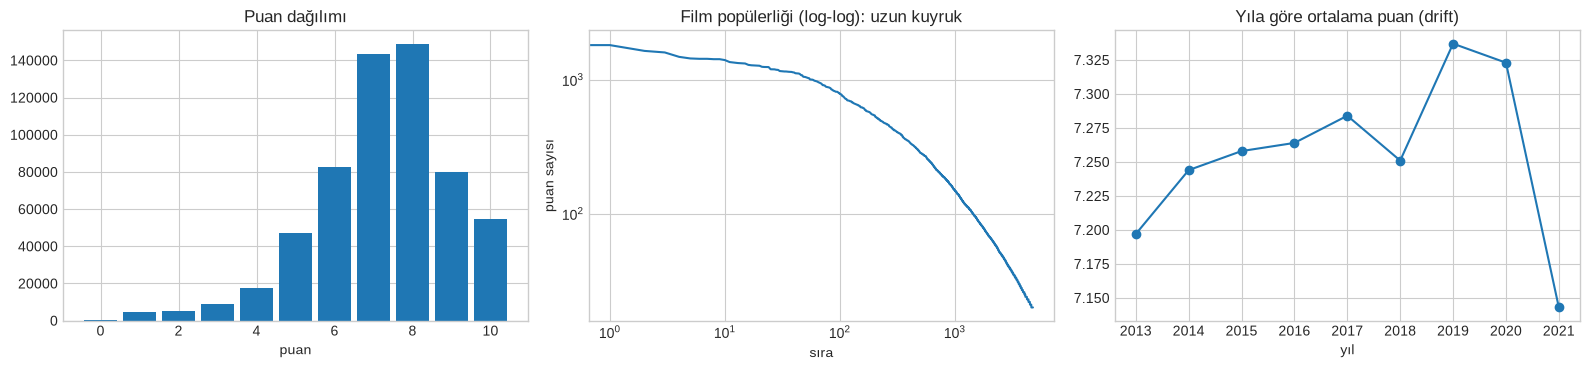

In [2]:
mt = pd.read_csv('data/mt_ratings.csv'); mv = pd.read_csv('data/mt_movies.csv')
mt['dt'] = pd.to_datetime(mt.ts, unit='s'); mt = mt.sort_values('ts', kind='stable').reset_index(drop=True)
nU, nI = mt.user.nunique(), mt.item.nunique()
print(f"MovieTweetings (süzülmüş): {len(mt):,} puan | {nU:,} kullanıcı | {nI:,} film | yoğunluk {len(mt)/(nU*nI):.4f} | {mt.dt.min():%Y-%m-%d} → {mt.dt.max():%Y-%m-%d}")
print("Puan dağılımı:", mt.rating.value_counts().sort_index().to_dict(), f"| ortalama {mt.rating.mean():.3f}")
cu = mt.groupby('user').size(); ci = mt.groupby('item').size()
top10 = ci.sort_values(ascending=False).head(int(0.1 * nI)).sum() / len(mt)
print(f"Kullanıcı başına puan: medyan {cu.median():.0f}, ort. {cu.mean():.1f}, maks {cu.max()} | Film başına: medyan {ci.median():.0f}, ort. {ci.mean():.1f}, maks {ci.max()} | en popüler %10 film puanların %{100*top10:.0f}'ini alıyor")
yr = mt.groupby(mt.dt.dt.year).rating.agg(['mean', 'size']).round(3).T; print("Yıla göre ortalama puan / puan sayısı:"); print(yr.to_string())

n = len(mt); g1, g2 = int(0.8 * n), int(0.9 * n); seen_u, seen_i = set(mt.user.iloc[:g1]), set(mt.item.iloc[:g1])
span_med = mt.groupby('user').ts.agg(lambda x: (x.max() - x.min()) / 86400).median(); gt = mt.iloc[g2:]; cold_g = (~gt.user.isin(seen_u) | ~gt.item.isin(seen_i)).mean()
print(f"\nKÜRESEL zamansal bölme denemesi (ilk %80 eğitim, son %10 test): testin %{100*cold_g:.0f}'u soğuk başlangıç (kullanıcı %{100*(~gt.user.isin(seen_u)).mean():.0f} yeni). Kullanıcıların ortanca etkinlik süresi yalnızca {span_med:.0f} gün (ilk-son puan arası) → kullanıcılar çoğunlukla kısa bir dönemde puanlıyor ve küresel bölmede test dönemi yeni kullanıcılarla doluyor; bu veride küresel bölme kişiselleştirmeyi ölçemez.")

# KULLANICI-İÇİ kronolojik bölme: mt zaten ts'e göre sıralı; cumcount kullanıcı içi sırayı verir
mt['pos'] = mt.groupby('user').cumcount(); mt['frac'] = mt.pos / mt.groupby('user').user.transform('size')
tr, va, te = mt[mt.frac < 0.8].copy(), mt[(mt.frac >= 0.8) & (mt.frac < 0.9)].copy(), mt[mt.frac >= 0.9].copy()
print(f"Kullanıcı-içi kronolojik bölme: eğitim {len(tr):,} | doğrulama {len(va):,} | test {len(te):,} | her kullanıcı için test puanları eğitim puanlarından SONRA (kendi zaman çizgisinde)")
uidx = {u: k for k, u in enumerate(tr.user.unique())}; iidx = {i: k for k, i in enumerate(tr.item.unique())}
for d in (tr, va, te): d['u'] = d.user.map(uidx); d['i'] = d.item.map(iidx)
for nm, d in (('doğrulama', va), ('test', te)):
    cold = d.u.isna() | d.i.isna(); print(f"{nm}: eğitimde olmayan kullanıcı/film satırı = {cold.sum():,} ({100*cold.mean():.1f}%; kullanıcı soğuk {d.u.isna().mean():.3f}, film soğuk {d.i.isna().mean():.3f}) → karşılaştırmalarda dışarıda")
va_c, te_c = va.dropna(subset=['u', 'i']).astype({'u': int, 'i': int}), te.dropna(subset=['u', 'i']).astype({'u': int, 'i': int})
tr = tr.astype({'u': int, 'i': int}); nUt, nIt = len(uidx), len(iidx); mu = tr.rating.mean()
print(f"Eğitim: {nUt:,} kullanıcı × {nIt:,} film, ortalama puan {mu:.3f} | karşılaştırma kümeleri: doğrulama {len(va_c):,}, test {len(te_c):,}")
print("Not: kullanıcı-içi bölme, diğer kullanıcıların GELECEĞİNİ eğitime katar (film popülerliği güncellenmiş olur); bu yaygın bir uzlaşma, ama tam zamansal olmadığı için sonuçlar hafif iyimserdir.")

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].hist(mt.rating, bins=np.arange(-.5, 11.5), rwidth=.85); ax[0].set(title='Puan dağılımı', xlabel='puan')
ax[1].loglog(np.sort(ci.values)[::-1]); ax[1].set(title='Film popülerliği (log-log): uzun kuyruk', xlabel='sıra', ylabel='puan sayısı')
ax[2].plot(yr.columns, yr.loc['mean'], marker='o'); ax[2].set(title='Yıla göre ortalama puan (drift)', xlabel='yıl'); plt.tight_layout(); plt.show()

## Adım 2 · Taban Çizgileri ve Yanlılık Modeli

`bias_fit`: $b_i=\sum_u(r_{ui}-\mu-b_u)/(\lambda+n_i)$ ve $b_u=\sum_i(r_{ui}-\mu-b_i)/(\lambda+n_u)$'yu dönüşümlü uygular. **Doğrulamalar:** (i) teorideki 6 puanlık elle örnek (tek geçiş), (ii) yakınsamış çözümün `sklearn.Ridge` (kullanıcı+film one-hot, `fit_intercept=False`) ile birebir eşleşmesi.

In [3]:
def bias_fit(u, i, r, nu, ni, lam_u, lam_i, mu_, iters=30):
    """Dönüşümlü kapalı form: önce b_i (b_u sabit), sonra b_u (b_i sabit). (b_u, b_i) döner."""
    bu, bi = np.zeros(nu), np.zeros(ni); cnt_u = np.bincount(u, minlength=nu); cnt_i = np.bincount(i, minlength=ni)
    for _ in range(iters):
        bi = np.bincount(i, weights=r - mu_ - bu[u], minlength=ni) / (lam_i + cnt_i)
        bu = np.bincount(u, weights=r - mu_ - bi[i], minlength=nu) / (lam_u + cnt_u)
    return bu, bi

# teorideki elle örnek: u1:(i1=5,i2=3) u2:(i1=4,i3=2) u3:(i2=4,i3=3)
uh = np.array([0, 0, 1, 1, 2, 2]); ih = np.array([0, 1, 0, 2, 1, 2]); rh = np.array([5, 3, 4, 2, 4, 3.]); mh = rh.mean()
bu1, bi1 = bias_fit(uh, ih, rh, 3, 3, 0, 0, mh, iters=1)
print(f"Elle örnek: mu={mh:.2f} | 1 geçiş: b_i={bi1.round(3)}, b_u={bu1.round(3)} | tahminler u1-i3 {mh+bu1[0]+bi1[2]:.2f}, u2-i2 {mh+bu1[1]+bi1[1]:.2f}, u3-i1 {mh+bu1[2]+bi1[0]:.2f} (beklenen 2.5, 3.0, 5.0)")
bu_c, bi_c = bias_fit(uh, ih, rh, 3, 3, 0, 0, mh, iters=500)
print(f"           yakınsayınca: b_i={bi_c.round(3)}, b_u={bu_c.round(3)} → tahminler {mh+bu_c[0]+bi_c[2]:.2f}, {mh+bu_c[1]+bi_c[1]:.2f}, {mh+bu_c[2]+bi_c[0]:.2f} (tek geçiş 'ilk yaklaşım'dır, çözüm değil)")
bu_s, bi_s = bias_fit(uh, ih, rh, 3, 3, 1, 1, mh, iters=1); print(f"           λ=1 ile ilk geçişte b_i1 = {bi_s[0]:.3f} (teori: 0.667)")

clip = lambda x: np.clip(x, 0, 10)
rm_tab = {}
rm_tab['genel ortalama'] = rmse(va_c.rating, mu)
im = tr.groupby('i').rating.agg(['sum', 'count']); item_mean = lambda lam: ((im['sum'] + lam * mu) / (im['count'] + lam)).reindex(range(nIt)).values
rm_tab['film ortalaması (λ=0)'] = rmse(va_c.rating, item_mean(0)[va_c.i.values])
lams = [0, 1, 3, 5, 10, 20, 50]
res_b = {}
for lam in lams:
    bu_, bi_ = bias_fit(tr.u.values, tr.i.values, tr.rating.values, nUt, nIt, lam, lam, mu); res_b[lam] = rmse(va_c.rating, clip(mu + bu_[va_c.u.values] + bi_[va_c.i.values]))
lam_best = min(res_b, key=res_b.get); rm_tab[f'yanlılık modeli (λ={lam_best})'] = res_b[lam_best]
print("\nDoğrulama RMSE:", {k: round(v, 4) for k, v in rm_tab.items()}); print("λ taraması (bias):", {k: round(v, 4) for k, v in res_b.items()})

Elle örnek: mu=3.50 | 1 geçiş: b_i=[ 1.  0. -1.], b_u=[ 0.  -0.5  0.5] | tahminler u1-i3 2.50, u2-i2 3.00, u3-i1 5.00 (beklenen 2.5, 3.0, 5.0)
           yakınsayınca: b_i=[ 1.333 -0.333 -1.   ], b_u=[ 0.    -0.667  0.667] → tahminler 2.50, 2.50, 5.50 (tek geçiş 'ilk yaklaşım'dır, çözüm değil)
           λ=1 ile ilk geçişte b_i1 = 0.667 (teori: 0.667)



Doğrulama RMSE: {'genel ortalama': 1.7375, 'film ortalaması (λ=0)': 1.5319, 'yanlılık modeli (λ=3)': 1.3705}
λ taraması (bias): {0: 1.3736, 1: 1.3715, 3: 1.3705, 5: 1.3711, 10: 1.3758, 20: 1.3895, 50: 1.4283}


In [4]:
# --- Ridge ile birebir doğrulama: tasarım matrisi [kullanıcı one-hot | film one-hot], hedef r-mu ---
lam_v = float(lam_best); t0 = time.time()
bu_o, bi_o = bias_fit(tr.u.values, tr.i.values, tr.rating.values, nUt, nIt, lam_v, lam_v, mu, iters=300)
Xoh = sp.hstack([sp.csr_matrix((np.ones(len(tr)), (np.arange(len(tr)), tr.u.values)), shape=(len(tr), nUt)),
                 sp.csr_matrix((np.ones(len(tr)), (np.arange(len(tr)), tr.i.values)), shape=(len(tr), nIt))]).tocsr()
rd, nw_r = quiet(lambda: Ridge(alpha=lam_v, fit_intercept=False, solver='sparse_cg', tol=1e-12, max_iter=5000).fit(Xoh, tr.rating.values - mu))
print(f"Ridge(alpha={lam_v:g}) eğitimi {time.time()-t0:.1f} s (uyarı {nw_r}) | b_u maks. fark {np.abs(rd.coef_[:nUt] - bu_o).max():.2e} | b_i maks. fark {np.abs(rd.coef_[nUt:] - bi_o).max():.2e}")
p_us = clip(mu + bu_o[va_c.u.values] + bi_o[va_c.i.values]); p_sk = clip(mu + rd.coef_[:nUt][va_c.u.values] + rd.coef_[nUt:][va_c.i.values])
print(f"Doğrulama RMSE: bizim {rmse(va_c.rating, p_us):.5f} | Ridge {rmse(va_c.rating, p_sk):.5f}")
BU, BI = bu_o, bi_o                                                    # sonraki adımlarda taban çizgisi olarak kullanılacak
rm_tab_te = {'genel ortalama': rmse(te_c.rating, mu), 'film ortalaması (λ=0)': rmse(te_c.rating, item_mean(0)[te_c.i.values]), 'yanlılık modeli': rmse(te_c.rating, clip(mu + BU[te_c.u.values] + BI[te_c.i.values]))}
print("Test RMSE:", {k: round(v, 4) for k, v in rm_tab_te.items()})
sd_r = te_c.rating.std(); print(f"Test puan sd = {sd_r:.3f} (genel ortalama RMSE'si ≈ sd); yanlılık modeli açıklanan varyans payı = %{100*(1-rm_tab_te['yanlılık modeli']**2/rm_tab_te['genel ortalama']**2):.1f}")
print(f"YORUM: Elle örnekteki tek geçiş (2.5/3.0/5.0) kodla aynı; yakınsayınca farklı sayılar çıkıyor — çünkü gerçek çözüm b_u ve b_i'yi AYNI ANDA ister. Yakınsamış çözüm Ridge ile maks. {max(np.abs(rd.coef_[:nUt]-bu_o).max(), np.abs(rd.coef_[nUt:]-bi_o).max()):.1e} içinde eşleşiyor: yanlılık modeli bir Ridge'dir.")
gain_l = res_b[0] - res_b[lam_best]
print(f"       Büzülme etkisi: λ=0'da doğrulama RMSE {res_b[0]:.4f}, λ={lam_best}'te {res_b[lam_best]:.4f} (fark {gain_l:.4f}): " + ("belirgin." if gain_l > 0.02 else "küçük — her kullanıcı ≥20, her film ≥20 puanlı olacak şekilde süzdüğümüz için sapmalar zaten yeterince iyi kestiriliyor; büzülme asıl, süzülmemiş seyrek veride (kullanıcı başına 1-2 puan) kritik olurdu."))
print(f"       Hiç kişiselleştirme yokken (yalnızca 'iyi film / cömert kullanıcı' etkisi) test RMSE {rm_tab_te['genel ortalama']:.3f} → {rm_tab_te['yanlılık modeli']:.3f}; yani ham puan varyansının %{100*(1-rm_tab_te['yanlılık modeli']**2/rm_tab_te['genel ortalama']**2):.0f}'ı yalnızca bu iki etkiyle açıklanıyor. Bundan sonraki her model bu çizginin altına inmeye çalışacak.")

Ridge(alpha=3) eğitimi 2.3 s (uyarı 0) | b_u maks. fark 1.56e-11 | b_i maks. fark 8.40e-11
Doğrulama RMSE: bizim 1.37050 | Ridge 1.37050
Test RMSE: {'genel ortalama': 1.748, 'film ortalaması (λ=0)': 1.5524, 'yanlılık modeli': 1.3951}
Test puan sd = 1.748 (genel ortalama RMSE'si ≈ sd); yanlılık modeli açıklanan varyans payı = %36.3
YORUM: Elle örnekteki tek geçiş (2.5/3.0/5.0) kodla aynı; yakınsayınca farklı sayılar çıkıyor — çünkü gerçek çözüm b_u ve b_i'yi AYNI ANDA ister. Yakınsamış çözüm Ridge ile maks. 8.4e-11 içinde eşleşiyor: yanlılık modeli bir Ridge'dir.
       Büzülme etkisi: λ=0'da doğrulama RMSE 1.3736, λ=3'te 1.3705 (fark 0.0031): küçük — her kullanıcı ≥20, her film ≥20 puanlı olacak şekilde süzdüğümüz için sapmalar zaten yeterince iyi kestiriliyor; büzülme asıl, süzülmemiş seyrek veride (kullanıcı başına 1-2 puan) kritik olurdu.
       Hiç kişiselleştirme yokken (yalnızca 'iyi film / cömert kullanıcı' etkisi) test RMSE 1.748 → 1.395; yani ham puan varyansının %36'ı yalnızc

## Adım 3 · Item-kNN: Bias-Düzeltilmiş Kosinüs Benzerliği

Film vektörleri = **yanlılık modelinin artıkları** $e_{ui}=r_{ui}-\mu-b_u-b_i$ (kullanıcı sütunları). Artıklar üzerinde kosinüs, "ortak kullanıcılar bu iki filmi beklentinin üstünde/altında birlikte mi puanlıyor?" sorusunu sorar (ham puanlarda kosinüs ise yalnızca "ikisini de çok puanlıyor"u ölçer). İki ek ayar: **ortak puan sayısı büzülmesi** $s_{ij}\cdot\dfrac{n_{ij}}{n_{ij}+\beta}$ ve her film için **en benzer $k$ komşu**. Tahmin: $\hat r_{ui}=\mu+b_u+b_i+\dfrac{\sum_j s_{ij}e_{uj}}{\sum_j|s_{ij}|+\varrho}$ ($j$: kullanıcının puanladığı komşular).

In [5]:
res_m = sp.csr_matrix((tr.rating.values - mu - BU[tr.u.values] - BI[tr.i.values], (tr.u.values, tr.i.values)), shape=(nUt, nIt))   # artık matrisi (seyrek)
Ind = sp.csr_matrix((np.ones(len(tr)), (tr.u.values, tr.i.values)), shape=(nUt, nIt))
nrm = np.sqrt(res_m.multiply(res_m).sum(0)).A1 + 1e-12
Rn = res_m @ sp.diags(1 / nrm); S_us = (Rn.T @ Rn).toarray(); np.fill_diagonal(S_us, 0.0)
S_sk = cosine_similarity(res_m.T.tocsr()); np.fill_diagonal(S_sk, 0.0)
print(f"Benzerlik matrisi {S_us.shape}: bizim vs sklearn.cosine_similarity maks. fark = {np.abs(S_us - S_sk).max():.2e}")
CO = (Ind.T @ Ind).toarray()

# teori bölümündeki 3x3 elle örnek (eksik=0 ham puanlar)
Rh = np.array([[5, 3, 0], [4, 0, 2], [0, 4, 3.]]); Sh = cosine_similarity(Rh.T)
pred_h = (Sh[2, 0] * 5 + Sh[2, 1] * 3) / (Sh[2, 0] + Sh[2, 1])
print(f"Elle örnek: cos(i1,i2)={Sh[0,1]:.3f}, cos(i1,i3)={Sh[0,2]:.3f}, cos(i2,i3)={Sh[1,2]:.3f} | u1 için i3 tahmini = {pred_h:.2f} (beklenen 3.69)")

def knn_matrix(S, k, beta):
    Sb = S * CO / (CO + beta) if beta else S
    top = np.argpartition(-np.abs(Sb), k, axis=1)[:, :k]; rows = np.repeat(np.arange(S.shape[0]), k)
    return sp.csr_matrix((Sb[rows, top.ravel()], (rows, top.ravel())), shape=S.shape)

def knn_predict(Sk, d, reg):
    uu, ii = d.u.values, d.i.values; A = res_m[uu]; B = Sk[ii]
    num = A.multiply(B).sum(1).A1; den = abs(B).multiply(Ind[uu]).sum(1).A1
    return np.clip(mu + BU[uu] + BI[ii] + num / (den + reg), 0, 10)

t0 = time.time(); rows_k = []
for beta in (0, 25):
    for k in (30, 100, 300):
        Sk = knn_matrix(S_us, k, beta)
        for reg in (0.5, 2.0): rows_k.append(dict(beta=beta, k=k, reg=reg, val_rmse=rmse(va_c.rating, knn_predict(Sk, va_c, reg))))
tab_k = pd.DataFrame(rows_k); bk = tab_k.loc[tab_k.val_rmse.idxmin()]
print(f"Izgara {len(tab_k)} yapılandırma, {time.time()-t0:.0f} s"); print(tab_k.pivot_table(index=['beta', 'k'], columns='reg', values='val_rmse').round(4).to_string())
Sk_best = knn_matrix(S_us, int(bk.k), bk.beta); p_knn_te = knn_predict(Sk_best, te_c, bk.reg)
rm_te = {'yanlılık modeli': rm_tab_te['yanlılık modeli'], f"item-kNN (β={bk.beta:g}, k={int(bk.k)}, ϱ={bk.reg:g})": rmse(te_c.rating, p_knn_te)}
print("Test RMSE:", {k: round(v, 4) for k, v in rm_te.items()})
gain_k = rm_te['yanlılık modeli'] - list(rm_te.values())[1]
print(f"YORUM: Bizim kosinüs matrisi sklearn ile makine hassasiyetinde aynı ve elle örnek (3.69) kodla eşleşiyor. Item-kNN yanlılık modelinin üstüne yalnızca {gain_k:.4f} RMSE kazandırıyor ({100*gain_k/rm_te['yanlılık modeli']:.1f}%): kişiselleştirme sinyali bu veride zayıf.")
print(f"       Izgarada {'ortak puan büzülmesi (β=25) yardımcı oldu' if tab_k[tab_k.beta==25].val_rmse.min() < tab_k[tab_k.beta==0].val_rmse.min() else 'ortak puan büzülmesi yardımcı olmadı'} (en iyi β=25: {tab_k[tab_k.beta==25].val_rmse.min():.4f} vs β=0: {tab_k[tab_k.beta==0].val_rmse.min():.4f}); komşu sayısı arttıkça hata düşüyor mu: k=30→300 farkı {tab_k[(tab_k.beta==bk.beta)&(tab_k.k==30)].val_rmse.min()-tab_k[(tab_k.beta==bk.beta)&(tab_k.k==300)].val_rmse.min():+.4f}.")

Benzerlik matrisi (4775, 4775): bizim vs sklearn.cosine_similarity maks. fark = 1.04e-11


Elle örnek: cos(i1,i2)=0.469, cos(i1,i3)=0.347, cos(i2,i3)=0.666 | u1 için i3 tahmini = 3.68 (beklenen 3.69)


Izgara 12 yapılandırma, 7 s
reg          0.5     2.0
beta k                  
0    30   1.3680  1.3670
     100  1.3667  1.3648
     300  1.3629  1.3624
25   30   1.3605  1.3655
     100  1.3574  1.3634
     300  1.3560  1.3621


Test RMSE: {'yanlılık modeli': 1.3951, 'item-kNN (β=25, k=300, ϱ=0.5)': 1.3837}
YORUM: Bizim kosinüs matrisi sklearn ile makine hassasiyetinde aynı ve elle örnek (3.69) kodla eşleşiyor. Item-kNN yanlılık modelinin üstüne yalnızca 0.0114 RMSE kazandırıyor (0.8%): kişiselleştirme sinyali bu veride zayıf.
       Izgarada ortak puan büzülmesi (β=25) yardımcı oldu (en iyi β=25: 1.3560 vs β=0: 1.3624); komşu sayısı arttıkça hata düşüyor mu: k=30→300 farkı +0.0045.


## Adım 4 · Matris Çarpanlarına Ayırma: ALS, SGD ve Sıfırla Doldurulmuş SVD

Yanlılıkları sabit tutup **artıklara** $e_{ui}\approx\mathbf p_u^\top\mathbf q_i$ MF uyduruyoruz (ortak öğrenme değil; yalnızca gizli etkileşimi yakalama). Üç şey gösterilecek:

1. **ALS'nin her adımı bir Ridge'dir** — tek kullanıcı güncellemesini `sklearn.Ridge` ile sayısal doğrularız; elle örnek $13/6=2{,}167$.
2. **Amaç fonksiyonu monoton azalır** (ALS garantisi).
3. **Sıfırla doldurulmuş SVD** (`svds`) eksik puanı "0" sayar ve çöker.

In [6]:
def als_explicit(Rc, k, lam, iters, seed=0, track=None):
    """Artık matrisi üzerinde ALS. Rc: CSR (kullanıcı x film). (P, Q, kayıp geçmişi, [her iterasyon sonrası track(P,Q)]) döner."""
    nu, ni = Rc.shape; rng = np.random.default_rng(seed); P = 0.1 * rng.standard_normal((nu, k)); Q = 0.1 * rng.standard_normal((ni, k))
    Rt = Rc.T.tocsr(); Ik = lam * np.eye(k); hist, tr_hist = [], []; rows_all = np.repeat(np.arange(nu), np.diff(Rc.indptr))
    for it in range(iters):
        for X, Y, M in ((P, Q, Rc), (Q, P, Rt)):
            ptr, ind, dat = M.indptr, M.indices, M.data
            for a in range(M.shape[0]):
                sl = slice(ptr[a], ptr[a + 1]); Ya = Y[ind[sl]]
                X[a] = np.linalg.solve(Ya.T @ Ya + Ik, Ya.T @ dat[sl])
        hist.append(np.sum((Rc.data - np.einsum('ij,ij->i', P[rows_all], Q[Rc.indices])) ** 2) + lam * (np.sum(P ** 2) + np.sum(Q ** 2)))
        if track is not None: tr_hist.append(track(P, Q))
    return P, Q, hist, tr_hist

# elle örnek (k=1, lam=1): q=(1,2), r=(3,5) -> p=13/6
q_h = np.array([[1.], [2.]]); r_h = np.array([3., 5.]); p_h = np.linalg.solve(q_h.T @ q_h + 1.0, q_h.T @ r_h)
print(f"Elle ALS: p = {p_h[0]:.4f} (13/6={13/6:.4f}) | tahminler {(q_h @ p_h).ravel().round(3)} | Ridge: {Ridge(alpha=1.0, fit_intercept=False).fit(q_h, r_h).coef_[0]:.4f}")

pred_va = lambda P, Q, d: np.clip(mu + BU[d.u.values] + BI[d.i.values] + np.einsum('ij,ij->i', P[d.u.values], Q[d.i.values]), 0, 10)
t0 = time.time(); rows_a = []; grid_a = [(k, lam) for k in (2, 4, 8, 16) for lam in (10, 20, 40, 80)]
for k, lam in grid_a:
    P_, Q_, h_, _ = als_explicit(res_m, k, lam, 12); rows_a.append(dict(k=k, lam=lam, val_rmse=rmse(va_c.rating, pred_va(P_, Q_, va_c)), monoton=bool(np.all(np.diff(h_) <= 1e-9 * h_[0]))))
tab_a = pd.DataFrame(rows_a); ba = tab_a.loc[tab_a.val_rmse.idxmin()]
print(f"ALS ızgarası ({len(tab_a)} yapılandırma, 12 iterasyon): {time.time()-t0:.0f} s"); print(tab_a.pivot(index='k', columns='lam', values='val_rmse').round(4).to_string())
print(f"Tüm yapılandırmalarda kayıp monoton azaldı mı? {tab_a.monoton.all()} | en iyi: k={int(ba.k)}, λ={int(ba.lam)} (val RMSE {ba.val_rmse:.4f}; yanlılık modeli {res_b[lam_best]:.4f})")

Elle ALS: p = 2.1667 (13/6=2.1667) | tahminler [2.167 4.333] | Ridge: 2.1667


ALS ızgarası (16 yapılandırma, 12 iterasyon): 51 s
lam      10      20      40      80
k                                  
2    1.3605  1.3544  1.3595  1.3705
4    1.3721  1.3543  1.3576  1.3705
8    1.4064  1.3642  1.3572  1.3705
16   1.4271  1.3666  1.3564  1.3705
Tüm yapılandırmalarda kayıp monoton azaldı mı? True | en iyi: k=4, λ=20 (val RMSE 1.3543; yanlılık modeli 1.3705)


Tek kullanıcı ALS adımı (u=3011, 1341 puan): kapalı form vs Ridge maks. fark = 2.22e-16


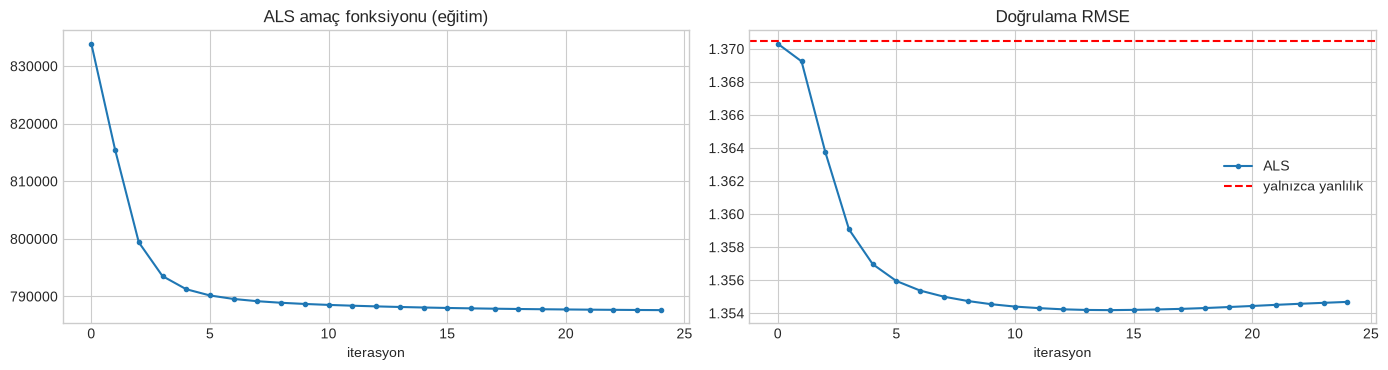

SGD (lr=0.01, λ=0.1, 25 epoch izlendi, 7 s): doğrulamada en iyi epoch 18 → RMSE 1.3585 | ALS 1.3542 | yalnızca yanlılık 1.3705
svds(ham puan matrisi, eksik=0, k=4): doğrulama RMSE 6.867 | svds(artık matrisi, eksik=0): 1.3645 | yalnızca yanlılık 1.3705
Test RMSE: {'yanlılık modeli': 1.3951, 'item-kNN (β=25, k=300, ϱ=0.5)': 1.3837, 'ALS': 1.3826, 'SGD': 1.3853}
YORUM: ALS'nin tek-kullanıcı adımı Ridge ile eşleşti (2e-16), amaç fonksiyonu her iterasyonda azaldı. Kazanç mütevazı: ALS test RMSE 1.3826 vs yanlılık 1.3951 (%0.9 iyileşme); SGD 1.3853, item-kNN 1.3837.
       Eğitim kaybı hep düşerken doğrulama RMSE en iyi 15. iterasyonda (1.3542); sonrasında neredeyse yatay, hafifçe yükseliyor (iterasyon 25: 1.3547) → aşırı uyum işareti; erken durdurma ucuz bir güvence. k büyüdükçe küçük λ'da doğrulama hatası kötüleşiyor (ızgara tablosu): kapasite arttıkça düzenleme gücü de artmalı.
       Sıfırla doldurulmuş HAM puan matrisinde SVD'nin RMSE'si 6.9: 'puanlanmamış = 0 puan' varsayımı felaket. B

In [7]:
# En iyi yapılandırmayla eğitim eğrisi + Ridge doğrulaması + test
k_b, lam_b = int(ba.k), float(ba.lam)
P_a, Q_a, hist_a, vh = als_explicit(res_m, k_b, lam_b, 25, track=lambda P, Q: rmse(va_c.rating, pred_va(P, Q, va_c)))
u0 = int(np.argmax(np.diff(res_m.indptr))); sl = slice(res_m.indptr[u0], res_m.indptr[u0 + 1]); Qu = Q_a[res_m.indices[sl]]
p_closed = np.linalg.solve(Qu.T @ Qu + lam_b * np.eye(k_b), Qu.T @ res_m.data[sl]); p_ridge = Ridge(alpha=lam_b, fit_intercept=False).fit(Qu, res_m.data[sl]).coef_
print(f"Tek kullanıcı ALS adımı (u={u0}, {sl.stop-sl.start} puan): kapalı form vs Ridge maks. fark = {np.abs(p_closed - p_ridge).max():.2e}")
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8)); ax[0].plot(hist_a, marker='o', ms=3); ax[0].set(title='ALS amaç fonksiyonu (eğitim)', xlabel='iterasyon'); ax[1].plot(vh, marker='o', ms=3, label='ALS'); ax[1].axhline(res_b[lam_best], c='r', ls='--', label='yalnızca yanlılık'); ax[1].set(title='Doğrulama RMSE', xlabel='iterasyon'); ax[1].legend(); plt.tight_layout(); plt.show()
it_b = int(np.argmin(vh)) + 1; P_a, Q_a, _, _ = als_explicit(res_m, k_b, lam_b, it_b)               # erken durdurma: doğrulamadaki en iyi iterasyon sayısı
p_als_te = pred_va(P_a, Q_a, te_c); rm_te['ALS'] = rmse(te_c.rating, p_als_te)

# --- SGD (mini-batch, aynı artık problemi) ---
def sgd_mf(u, i, e, nu, ni, k, lam, lr, epochs, bs=2048, seed=0, track=None):
    """Mini-batch SGD: her gözlem için p_u += lr*(err*q_i - lam*p_u), q_i += lr*(err*p_u - lam*q_i). Gradyanlar batch içinde toplanır (np.add.at)."""
    rng = np.random.default_rng(seed); P = 0.1 * rng.standard_normal((nu, k)); Q = 0.1 * rng.standard_normal((ni, k)); n_ = len(u); out = []
    for ep in range(epochs):
        perm = rng.permutation(n_)
        for s0 in range(0, n_, bs):
            b = perm[s0:s0 + bs]; ub, ib = u[b], i[b]; err = e[b] - np.einsum('ij,ij->i', P[ub], Q[ib])
            gP = np.zeros_like(P); gQ = np.zeros_like(Q)
            np.add.at(gP, ub, err[:, None] * Q[ib] - lam * P[ub]); np.add.at(gQ, ib, err[:, None] * P[ub] - lam * Q[ib])
            P += lr * gP; Q += lr * gQ
        if track is not None: out.append(track(P, Q))
    return P, Q, out
e_tr = tr.rating.values - mu - BU[tr.u.values] - BI[tr.i.values]; t0 = time.time(); trk = lambda P, Q: rmse(va_c.rating, pred_va(P, Q, va_c))
_, _, vh_s = sgd_mf(tr.u.values, tr.i.values, e_tr, nUt, nIt, k_b, 0.1, 0.01, 25, track=trk); ep_b = int(np.argmin(vh_s)) + 1
P_s, Q_s, _ = sgd_mf(tr.u.values, tr.i.values, e_tr, nUt, nIt, k_b, 0.1, 0.01, ep_b)                 # erken durdurma: doğrulamadaki en iyi epoch kadar eğit
print(f"SGD (lr=0.01, λ=0.1, 25 epoch izlendi, {time.time()-t0:.0f} s): doğrulamada en iyi epoch {ep_b} → RMSE {min(vh_s):.4f} | ALS {min(vh):.4f} | yalnızca yanlılık {res_b[lam_best]:.4f}")
rm_te['SGD'] = rmse(te_c.rating, pred_va(P_s, Q_s, te_c))

# --- sıfırla doldurulmuş SVD ---
Rraw = sp.csr_matrix((tr.rating.values, (tr.u.values, tr.i.values)), shape=(nUt, nIt)).astype(float)
U_, s_, Vt_ = spla.svds(Rraw, k=k_b); p_svd = np.clip(np.einsum('ij,ij->i', (U_ * s_)[va_c.u.values], Vt_.T[va_c.i.values]), 0, 10)
U2, s2, Vt2 = spla.svds(res_m, k=k_b); p_svd2 = np.clip(mu + BU[va_c.u.values] + BI[va_c.i.values] + np.einsum('ij,ij->i', (U2 * s2)[va_c.u.values], Vt2.T[va_c.i.values]), 0, 10)
print(f"svds(ham puan matrisi, eksik=0, k={k_b}): doğrulama RMSE {rmse(va_c.rating, p_svd):.3f} | svds(artık matrisi, eksik=0): {rmse(va_c.rating, p_svd2):.4f} | yalnızca yanlılık {res_b[lam_best]:.4f}")
print("Test RMSE:", {k: round(v, 4) for k, v in rm_te.items()})
s_res = rmse(va_c.rating, p_svd2)
print(f"YORUM: ALS'nin tek-kullanıcı adımı Ridge ile eşleşti ({np.abs(p_closed - p_ridge).max():.0e}), amaç fonksiyonu {'her iterasyonda azaldı' if np.all(np.diff(hist_a) <= 1e-9*hist_a[0]) else 'her zaman azalmadı'}. Kazanç mütevazı: ALS test RMSE {rm_te['ALS']:.4f} vs yanlılık {rm_tab_te['yanlılık modeli']:.4f} (%{100*(rm_tab_te['yanlılık modeli']-rm_te['ALS'])/rm_tab_te['yanlılık modeli']:.1f} iyileşme); SGD {rm_te['SGD']:.4f}, item-kNN {rm_te[[k for k in rm_te if k.startswith('item-kNN')][0]]:.4f}.")
print(f"       Eğitim kaybı hep düşerken doğrulama RMSE en iyi {it_b}. iterasyonda ({min(vh):.4f}); sonrasında {'belirgin biçimde yükseliyor' if vh[-1] > min(vh) + 2e-3 else 'neredeyse yatay, hafifçe yükseliyor' if vh[-1] > min(vh) + 1e-4 else 'yatay'} (iterasyon {len(vh)}: {vh[-1]:.4f}) → aşırı uyum işareti; erken durdurma ucuz bir güvence. k büyüdükçe küçük λ'da doğrulama hatası kötüleşiyor (ızgara tablosu): kapasite arttıkça düzenleme gücü de artmalı.")
print(f"       Sıfırla doldurulmuş HAM puan matrisinde SVD'nin RMSE'si {rmse(va_c.rating, p_svd):.1f}: 'puanlanmamış = 0 puan' varsayımı felaket. Buna karşılık artık matrisinde (eksik = 0 = 'beklenenden sapma yok') svds {s_res:.4f} ile yanlılık modelini ({res_b[lam_best]:.4f}) bile geçiyor: sorun SVD'nin kendisi değil, sıfırın ANLAMI. Yine de gözlenen hücrelere özel ALS kaybı ({min(vh):.4f}) daha iyi.")
print("       SGD öğrenme oranı ve düzenleme ayarı ister (burada yalnızca kaba bir ayar yapıldı; yanlış ölçeklenmiş bir öğrenme oranı/düzenleme ile model hiç öğrenmeyip başlangıçtaki yanlılık modelinde kalabilir); ALS ise daha az duyarlı ve paralellenebilir.")

## Adım 4b · RMSE İyi Ama Sıralama? (MovieTweetings'te Top-N)

Gerçek ürün "kullanıcıya hangi 10 filmi gösterelim?"dir, RMSE değil. Test puanlarından **≥ 8** olanları "ilgili" sayıp, her kullanıcı için **eğitimde görmediği tüm filmleri** puanla-sırala (tam katalog sıralaması, örneklenmiş negatif yok) ve **HR@10, Recall@10, NDCG@10**, ayrıca **katalog kapsamı** ve önerilerin ortalama popülerliğini ölçelim. Karşılaştırılanlar: popülerlik, yalnızca film yanlılığı $b_i$ (en yüksek ortalama puanlılar), item-kNN, ALS.

In [8]:
def rank_metrics(S, train_csr, test_pos_csr, K=10):
    """S: (kullanıcı x öğe) skorlar. Eğitimde görülenler elenir. Test'te ilgili öğesi olan kullanıcılar üzerinden ortalama metrikler + kapsam + ort. log-popülerlik."""
    users = np.where(np.diff(test_pos_csr.indptr) > 0)[0]; S = np.array(S[users], dtype=np.float32); tr_sub = train_csr[users].tocoo()
    S[tr_sub.row, tr_sub.col] = -np.inf
    top = np.argpartition(-S, K, axis=1)[:, :K]; ordr = np.argsort(-np.take_along_axis(S, top, 1), axis=1); top = np.take_along_axis(top, ordr, 1)
    T = test_pos_csr[users].toarray() > 0; hits = np.take_along_axis(T, top, 1); n_rel = T.sum(1)
    disc = 1 / np.log2(np.arange(2, K + 2)); dcg = (hits * disc).sum(1); idcg = np.array([disc[:min(n, K)].sum() for n in n_rel])
    pop = np.asarray(train_csr.sum(0)).ravel()
    return dict(HR=hits.any(1).mean(), Recall=(hits.sum(1) / n_rel).mean(), NDCG=(dcg / idcg).mean(), kapsam=len(np.unique(top)) / train_csr.shape[1], ort_log_pop=np.log1p(pop[top]).mean(), n_kullanıcı=len(users))

pos = te_c[te_c.rating >= 8]; T_pos = sp.csr_matrix((np.ones(len(pos)), (pos.u.values, pos.i.values)), shape=(nUt, nIt))
Tr_bin = sp.csr_matrix((np.ones(len(tr)), (tr.u.values, tr.i.values)), shape=(nUt, nIt))
pop_i = np.asarray(Tr_bin.sum(0)).ravel()
scores = {}
scores['popülerlik'] = np.tile(pop_i, (nUt, 1)).astype(np.float32)
scores['yalnızca film yanlılığı b_i'] = np.tile(BI, (nUt, 1)).astype(np.float32)
Sk_b = knn_matrix(S_us, int(bk.k), bk.beta); sc_knn = np.zeros((nUt, nIt), np.float32)
for a in range(0, nUt, 2000):
    sl_ = slice(a, min(a + 2000, nUt)); num = (res_m[sl_] @ Sk_b.T).toarray(); den = (Ind[sl_] @ abs(Sk_b).T).toarray(); sc_knn[sl_] = num / (den + bk.reg)
scores['item-kNN'] = sc_knn; scores['ALS (artık MF)'] = (P_a @ Q_a.T + BI[None, :]).astype(np.float32)
rng_r = np.random.default_rng(0); scores['rastgele'] = rng_r.random((nUt, nIt)).astype(np.float32)
rows = {nm: rank_metrics(sc, Tr_bin, T_pos, 10) for nm, sc in scores.items()}; tab_rk = pd.DataFrame(rows).T
print(f"İlgili test puanı (≥8) olan kullanıcı: {int(tab_rk.n_kullanıcı.iloc[0]):,} | ilgili satır {len(pos):,} | K=10"); print(tab_rk.drop(columns='n_kullanıcı').round(4).to_string())
best_rk = tab_rk.NDCG.idxmax()
print(f"YORUM: NDCG@10'a göre en iyi: {best_rk} ({tab_rk.NDCG.max():.4f}); rastgele {tab_rk.loc['rastgele','NDCG']:.4f}. Kişiselleştirilmiş modeller: item-kNN {tab_rk.loc['item-kNN','NDCG']:.4f}, ALS {tab_rk.loc['ALS (artık MF)','NDCG']:.4f}; popülerlik {tab_rk.loc['popülerlik','NDCG']:.4f}.")
print(f"       " + ("Popülerlik taban çizgisi RMSE'de işe yarayan kişiselleştirilmiş modellerin ikisini de sıralamada geçiyor: RMSE'yi (gözlenen hücrelerde puan tahmini) optimize etmek, 'hangi 10 filmi göstereyim' sorusuna cevap vermiyor." if best_rk == 'popülerlik' else "Kişiselleştirilmiş model popülerliği geçiyor.") + f" 'Yalnızca film yanlılığı' (en yüksek ortalama puanlılar) NDCG {tab_rk.loc['yalnızca film yanlılığı b_i','NDCG']:.4f} ve ortalama log-popülerlik {tab_rk.loc['yalnızca film yanlılığı b_i','ort_log_pop']:.2f}: az sayıda yüksek puanlı, az bilinen filme kayıyor.")
print(f"       Kapsam: popülerlik {tab_rk.loc['popülerlik','kapsam']:.3f}, kNN {tab_rk.loc['item-kNN','kapsam']:.3f}, ALS {tab_rk.loc['ALS (artık MF)','kapsam']:.3f}: kişiselleştirme ALS'de bile katalogun küçük bir kısmını kullanıyor. Doğruluk ile keşif/çeşitlilik arasındaki dengeyi gösteren sütunlar ort_log_pop ve kapsam.")
del scores

İlgili test puanı (≥8) olan kullanıcı: 7,616 | ilgili satır 27,236 | K=10
                                 HR  Recall    NDCG  kapsam  ort_log_pop
popülerlik                   0.0773  0.0318  0.0208  0.0157       7.2119
yalnızca film yanlılığı b_i  0.0230  0.0080  0.0048  0.0046       5.2914
item-kNN                     0.0555  0.0204  0.0136  0.6021       5.5828
ALS (artık MF)               0.0612  0.0190  0.0120  0.0320       5.3876
rastgele                     0.0084  0.0022  0.0015  1.0000       3.9841
YORUM: NDCG@10'a göre en iyi: popülerlik (0.0208); rastgele 0.0015. Kişiselleştirilmiş modeller: item-kNN 0.0136, ALS 0.0120; popülerlik 0.0208.
       Popülerlik taban çizgisi RMSE'de işe yarayan kişiselleştirilmiş modellerin ikisini de sıralamada geçiyor: RMSE'yi (gözlenen hücrelerde puan tahmini) optimize etmek, 'hangi 10 filmi göstereyim' sorusuna cevap vermiyor. 'Yalnızca film yanlılığı' (en yüksek ortalama puanlılar) NDCG 0.0048 ve ortalama log-popülerlik 5.29: az sayıda yüksek

## Adım 5 · Bölme Stratejisinin Etkisi: Rastgele vs Kullanıcı-İçi Kronolojik

Aynı modeller (yanlılık ve ALS), aynı eğitim boyutu, yalnızca **bölme** farklı: puanların %80/10/10'u **rastgele** ayrılıyor. Rastgele bölmede bir kullanıcının *sonraki* puanları eğitime girer; model "geleceği görerek" öğrenir. RMSE ve NDCG@10 farkı bu iyimserliği ölçer.

In [9]:
def fit_eval(trn, tst, k=k_b, lam=lam_b, iters=it_b):
    uid = {u: j for j, u in enumerate(trn.user.unique())}; iid = {i: j for j, i in enumerate(trn.item.unique())}
    a = trn.assign(u=trn.user.map(uid), i=trn.item.map(iid)); b = tst.assign(u=tst.user.map(uid), i=tst.item.map(iid)).dropna(subset=['u', 'i']).astype({'u': int, 'i': int})
    mu_ = a.rating.mean(); bu_, bi_ = bias_fit(a.u.values, a.i.values, a.rating.values, len(uid), len(iid), 3, 3, mu_, iters=60)
    r_ = sp.csr_matrix((a.rating.values - mu_ - bu_[a.u.values] - bi_[a.i.values], (a.u.values, a.i.values)), shape=(len(uid), len(iid)))
    P, Q, _, _ = als_explicit(r_, k, lam, iters)
    pb = np.clip(mu_ + bu_[b.u.values] + bi_[b.i.values], 0, 10); pa = np.clip(pb + np.einsum('ij,ij->i', P[b.u.values], Q[b.i.values]), 0, 10)
    pos_ = b[b.rating >= 8]; Tt = sp.csr_matrix((np.ones(len(pos_)), (pos_.u.values, pos_.i.values)), shape=(len(uid), len(iid)))
    Trb = sp.csr_matrix((np.ones(len(a)), (a.u.values, a.i.values)), shape=(len(uid), len(iid)))
    nd = rank_metrics((P @ Q.T + bi_[None, :]).astype(np.float32), Trb, Tt, 10)['NDCG']
    return dict(bias_RMSE=rmse(b.rating, pb), ALS_RMSE=rmse(b.rating, pa), ALS_NDCG10=nd, n_test=len(b))

rng_s = np.random.default_rng(3); msk = rng_s.random(len(mt))
rand_tr, rand_te = mt[msk < 0.9], mt[msk >= 0.9]; chron_tr, chron_te = mt[mt.frac < 0.9], mt[mt.frac >= 0.9]
rows = {'rastgele %90/%10': fit_eval(rand_tr, rand_te), 'kullanıcı-içi kronolojik %90/%10': fit_eval(chron_tr, chron_te)}
tab_sp = pd.DataFrame(rows).T; print(tab_sp.round(4).to_string())
d_rm = tab_sp.ALS_RMSE.iloc[1] - tab_sp.ALS_RMSE.iloc[0]; d_nd = tab_sp.ALS_NDCG10.iloc[0] - tab_sp.ALS_NDCG10.iloc[1]
print(f"YORUM: ALS RMSE rastgele bölmede {tab_sp.ALS_RMSE.iloc[0]:.4f}, kronolojikte {tab_sp.ALS_RMSE.iloc[1]:.4f}: rastgele bölme RMSE'yi {d_rm:.3f} (%{100*d_rm/tab_sp.ALS_RMSE.iloc[1]:.1f}) iyimser gösteriyor — bu fark, Adım 4'te ALS'nin yanlılık modeline getirdiği kazançtan ({rm_tab_te['yanlılık modeli']-rm_te['ALS']:.3f}) büyük: bölme stratejisi, model farkından daha çok sonucu etkiliyor.")
print(f"       NDCG@10 ise rastgele {tab_sp.ALS_NDCG10.iloc[0]:.4f}, kronolojik {tab_sp.ALS_NDCG10.iloc[1]:.4f}: yön RMSE'dekinin tersi ({'rastgele daha yüksek' if d_nd > 0 else 'rastgele daha düşük'}); bu veride sıralama metriği bölmeye tutarlı biçimde iyimserlik göstermedi (test kümeleri de farklı: {int(tab_sp.n_test.iloc[0]):,} vs {int(tab_sp.n_test.iloc[1]):,} puan; tek tohumla ölçüldü, farkın işareti gürültü olabilir). Genel ilke yine de değişmiyor: üretim zamanı ileri aktığı için kronolojik protokol esas alınmalı.")

                                  bias_RMSE  ALS_RMSE  ALS_NDCG10   n_test
rastgele %90/%10                     1.3569    1.3355      0.0126  59667.0
kullanıcı-içi kronolojik %90/%10     1.3854    1.3686      0.0159  55817.0
YORUM: ALS RMSE rastgele bölmede 1.3355, kronolojikte 1.3686: rastgele bölme RMSE'yi 0.033 (%2.4) iyimser gösteriyor — bu fark, Adım 4'te ALS'nin yanlılık modeline getirdiği kazançtan (0.012) büyük: bölme stratejisi, model farkından daha çok sonucu etkiliyor.
       NDCG@10 ise rastgele 0.0126, kronolojik 0.0159: yön RMSE'dekinin tersi (rastgele daha düşük); bu veride sıralama metriği bölmeye tutarlı biçimde iyimserlik göstermedi (test kümeleri de farklı: 59,667 vs 55,817 puan; tek tohumla ölçüldü, farkın işareti gürültü olabilir). Genel ilke yine de değişmiyor: üretim zamanı ileri aktığı için kronolojik protokol esas alınmalı.


## Adım 6 · Goodbooks: Kapalı Geri Bildirim, HKV-ALS ve Popülerlik Yanlılığı

3.000 rastgele kullanıcı, 9.993 kitap, 335.699 etkileşim (kullanıcı başına ortalama 112; yoğunluk %1,1). Etkileşim = kullanıcı kitabı raflayıp puanlamış; **etkileşimin kendisini** sinyal kabul ediyoruz (ikili $p_{ui}$). Her kullanıcının etkileşimleri rastgele **%70 eğitim / %10 doğrulama / %20 test**; **ilgili** = ayrılan etkileşimler içinde puanı $\ge 4$ olanlar. Karşılaştırma: rastgele, popülerlik, item-kNN (ikili kosinüs), HKV-ALS. $\alpha$, $k$, $\lambda$ **doğrulamada** seçilir, test yalnızca bir kez.

In [10]:
gb = pd.read_csv('data/gb_ratings.csv'); books = pd.read_csv('data/gb_books.csv')
gu = {u: j for j, u in enumerate(gb.user_id.unique())}; gi = {b: j for j, b in enumerate(np.sort(gb.book_id.unique()))}
gb['u'] = gb.user_id.map(gu); gb['i'] = gb.book_id.map(gi); nGU, nGI = len(gu), len(gi)
print(f"Goodbooks örneklemi: {len(gb):,} etkileşim | {nGU:,} kullanıcı | {nGI:,} kitap | yoğunluk {len(gb)/(nGU*nGI):.4f} | puan dağılımı {gb.rating.value_counts().sort_index().to_dict()}")
rg = np.random.default_rng(11); gb['split'] = np.where((z := rg.random(len(gb))) < 0.7, 'tr', np.where(z < 0.8, 'va', 'te'))
mk = lambda d: sp.csr_matrix((np.ones(len(d)), (d.u.values, d.i.values)), shape=(nGU, nGI))
Xg = mk(gb[gb.split == 'tr']); Vg = mk(gb[(gb.split == 'va') & (gb.rating >= 4)]); Tg = mk(gb[(gb.split == 'te') & (gb.rating >= 4)])
pop_g = np.asarray(Xg.sum(0)).ravel(); print(f"Eğitim {Xg.nnz:,} | doğrulama ilgili {Vg.nnz:,} | test ilgili {Tg.nnz:,} | kitap başına eğitim etkileşimi: medyan {np.median(pop_g):.0f}, maks {pop_g.max():.0f}, sıfır etkileşimli kitap {int((pop_g==0).sum())}")
top20 = np.sort(pop_g)[::-1][:int(0.2 * nGI)].sum() / pop_g.sum(); print(f"En popüler %20 kitap eğitim etkileşimlerinin %{100*top20:.0f}'ini alıyor (uzun kuyruk)")

# --- item-kNN (ikili kosinüs), sıfırdan; sklearn ile küçük alt kümede doğrula ---
def item_knn_topk(X, k, chunk=1500):
    n = np.asarray(X.sum(0)).ravel(); inv = sp.diags(1 / np.sqrt(np.maximum(n, 1))); Xn = (X @ inv).tocsc(); rows, cols, vals = [], [], []
    for a in range(0, X.shape[1], chunk):
        blk = (Xn[:, a:a + chunk].T @ Xn).toarray()
        for r_ in range(blk.shape[0]): blk[r_, a + r_] = 0.0
        top = np.argpartition(-blk, k, axis=1)[:, :k]; rr = np.repeat(np.arange(blk.shape[0]), k)
        rows.append(rr + a); cols.append(top.ravel()); vals.append(blk[rr, top.ravel()])
    return sp.csr_matrix((np.concatenate(vals), (np.concatenate(rows), np.concatenate(cols))), shape=(X.shape[1], X.shape[1]))

sub = np.arange(400); S_chk = cosine_similarity(Xg[:, sub].T); np.fill_diagonal(S_chk, 0)
Sk_full = item_knn_topk(Xg[:, sub], k=399); print(f"item-kNN benzerliği (400 kitap, tüm komşular) sklearn.cosine_similarity ile maks. fark = {np.abs(Sk_full.toarray() - S_chk).max():.2e}")

t0 = time.time(); knn_sc = {}
for kk in (20, 50, 100, 200):
    Sk = item_knn_topk(Xg, kk); knn_sc[kk] = (Xg @ Sk.T).toarray().astype(np.float32)
print(f"item-kNN skorları (k=20, 50, 100, 200): {time.time()-t0:.0f} s")

Goodbooks örneklemi: 335,699 etkileşim | 3,000 kullanıcı | 9,993 kitap | yoğunluk 0.0112 | puan dağılımı {1: 7092, 2: 20365, 3: 75939, 4: 119193, 5: 113110}


Eğitim 234,733 | doğrulama ilgili 23,360 | test ilgili 46,507 | kitap başına eğitim etkileşimi: medyan 10, maks 875, sıfır etkileşimli kitap 28
En popüler %20 kitap eğitim etkileşimlerinin %68'ini alıyor (uzun kuyruk)
item-kNN benzerliği (400 kitap, tüm komşular) sklearn.cosine_similarity ile maks. fark = 0.00e+00


item-kNN skorları (k=20, 50, 100, 200): 7 s


In [11]:
def als_implicit(X, k, lam, alpha, iters, seed=0):
    """HKV: x_u = (Y'Y + alpha*Y_u'Y_u + lam I)^-1 (1+alpha) sum_{i in N_u} y_i  (ikili veri: p=1, c=1+alpha). (X_f, Y_f) döner."""
    nu, ni = X.shape; rng = np.random.default_rng(seed); Y = 0.1 * rng.standard_normal((ni, k)); Xf = np.zeros((nu, k)); Xt = X.T.tocsr(); Ik = lam * np.eye(k)
    for it in range(iters):
        for F, G, M in ((Xf, Y, X), (Y, Xf, Xt)):
            GtG = G.T @ G; ptr, ind = M.indptr, M.indices
            for a in range(M.shape[0]):
                idx = ind[ptr[a]:ptr[a + 1]]
                if len(idx) == 0: F[a] = 0.0; continue
                Gu = G[idx]; F[a] = np.linalg.solve(GtG + alpha * Gu.T @ Gu + Ik, (1 + alpha) * Gu.sum(0))
    return Xf, Y

# elle örnek (k=1, lam=1, alpha=2): y=(1,.2,.5), u interacted a,c
yh = np.array([[1.], [0.2], [0.5]]); Xh = sp.csr_matrix(np.array([[1., 0., 1.]]))
xh = np.linalg.solve(yh.T @ yh + 2 * yh[[0, 2]].T @ yh[[0, 2]] + 1.0, 3 * yh[[0, 2]].sum(0))
print(f"Elle HKV: x = {xh[0]:.4f} (4.5/4.79 = {4.5/4.79:.4f}) | skorlar {(yh @ xh).ravel().round(3)} (beklenen 0.94, 0.19, 0.47)")

# ağırlıklı Ridge denkliği: sklearn.Ridge(sample_weight=c), TÜM öğeler hedef
Xf0, Y0 = als_implicit(Xg, 16, 10.0, 20.0, 3)
u0 = int(np.argmax(np.diff(Xg.indptr))); p_vec = np.zeros(nGI); idx0 = Xg.indices[Xg.indptr[u0]:Xg.indptr[u0 + 1]]; p_vec[idx0] = 1.0; c_vec = np.ones(nGI); c_vec[idx0] += 20.0
x_closed = np.linalg.solve(Y0.T @ Y0 + 20.0 * Y0[idx0].T @ Y0[idx0] + 10.0 * np.eye(16), (1 + 20.0) * Y0[idx0].sum(0))
x_ridge = Ridge(alpha=10.0, fit_intercept=False).fit(Y0, p_vec, sample_weight=c_vec).coef_
print(f"Tek kullanıcı HKV güncellemesi (u={u0}, {len(idx0)} etkileşim): kapalı form vs sklearn Ridge(sample_weight=c, tüm {nGI:,} öğe hedef) maks. fark = {np.abs(x_closed - x_ridge).max():.2e}")

Elle HKV: x = 0.9395 (4.5/4.79 = 0.9395) | skorlar [0.939 0.188 0.47 ] (beklenen 0.94, 0.19, 0.47)


Tek kullanıcı HKV güncellemesi (u=1531, 139 etkileşim): kapalı form vs sklearn Ridge(sample_weight=c, tüm 9,993 öğe hedef) maks. fark = 4.83e-15


In [12]:
t0 = time.time(); rows_i = []; models_i = {}
for k, lam, alpha in [(16, 10, 1), (16, 10, 3), (16, 10, 10), (32, 10, 3), (32, 30, 3), (64, 10, 3), (64, 30, 3), (32, 10, 40)]:
    Xf, Yf = als_implicit(Xg, k, lam, alpha, 10); sc = (Xf @ Yf.T).astype(np.float32); m_ = rank_metrics(sc, Xg, Vg, 10); m_.update(k=k, lam=lam, alpha=alpha); rows_i.append(m_); models_i[(k, lam, alpha)] = (Xf, Yf)
tab_i = pd.DataFrame(rows_i)[['k', 'lam', 'alpha', 'HR', 'Recall', 'NDCG', 'kapsam', 'ort_log_pop']]; print(f"HKV-ALS ızgarası (10 iterasyon, doğrulama NDCG@10), {time.time()-t0:.0f} s"); print(tab_i.round(4).to_string(index=False))
bi_cfg = tuple(int(x) for x in tab_i.loc[tab_i.NDCG.idxmax(), ['k', 'lam', 'alpha']]); Xf, Yf = models_i[bi_cfg]
kv = {kk: rank_metrics(s_, Xg, Vg, 10)['NDCG'] for kk, s_ in knn_sc.items()}; kbest = max(kv, key=kv.get)
print(f"\nDoğrulama NDCG@10: item-kNN {', '.join(f'k={a}: {b:.4f}' for a, b in kv.items())} → k={kbest} | HKV-ALS en iyi {bi_cfg}: {tab_i.NDCG.max():.4f}")
print(f"Not: seçilen k={bi_cfg[0]} " + ("ızgaranın en büyük değeri (64): daha büyük k daha iyi olabilir; ALS sonucunu 'ayar sınırlı' diye okuyun." if bi_cfg[0] == 64 else "ızgaranın iç bölgesinde."))

HKV-ALS ızgarası (10 iterasyon, doğrulama NDCG@10), 42 s
 k  lam  alpha     HR  Recall   NDCG  kapsam  ort_log_pop
16   10      1 0.5344  0.1077 0.1147  0.0411       5.8300
16   10      3 0.5213  0.1064 0.1109  0.0524       5.7593
16   10     10 0.4921  0.0983 0.1002  0.0775       5.6053
32   10      3 0.5847  0.1247 0.1270  0.0800       5.5808
32   30      3 0.5834  0.1246 0.1279  0.0690       5.6791
64   10      3 0.6032  0.1335 0.1313  0.1120       5.3963
64   30      3 0.6095  0.1353 0.1355  0.0932       5.5280
32   10     40 0.4539  0.0881 0.0850  0.1982       4.9975



Doğrulama NDCG@10: item-kNN k=20: 0.1502, k=50: 0.1451, k=100: 0.1426, k=200: 0.1382 → k=20 | HKV-ALS en iyi (64, 30, 3): 0.1355
Not: seçilen k=64 ızgaranın en büyük değeri (64): daha büyük k daha iyi olabilir; ALS sonucunu 'ayar sınırlı' diye okuyun.


In [13]:
# Test: eğitim + doğrulama etkileşimleri birlikte "geçmiş" (görülenler elenir); ilgili = test puanı >= 4
Xg_all = mk(gb[gb.split != 'te']); k_, lam_, al_ = bi_cfg; t0 = time.time()
Xf_t, Yf_t = als_implicit(Xg_all, k_, lam_, al_, 10); pop_all = np.asarray(Xg_all.sum(0)).ravel(); Sk_t = item_knn_topk(Xg_all, kbest)
sc_t = {'rastgele': np.random.default_rng(0).random((nGU, nGI)).astype(np.float32), 'popülerlik': np.tile(pop_all, (nGU, 1)).astype(np.float32),
        f'item-kNN (k={kbest})': (Xg_all @ Sk_t.T).toarray().astype(np.float32), f'HKV-ALS (k={k_}, λ={lam_}, α={al_})': (Xf_t @ Yf_t.T).astype(np.float32)}
res_g = {}
for K in (10, 20):
    res_g[K] = pd.DataFrame({nm: rank_metrics(s_, Xg_all, Tg, K) for nm, s_ in sc_t.items()}).T
print(f"(son eğitim {time.time()-t0:.0f} s)"); 
for K in (10, 20): print(f"\nTest, K={K}:"); print(res_g[K].drop(columns='n_kullanıcı').round(4).to_string())
r10 = res_g[10]; als_n, pop_n = r10.iloc[3], r10.loc['popülerlik']; knn_n = r10.iloc[2]
print(f"\nYORUM: NDCG@10: popülerlik {pop_n.NDCG:.4f}, item-kNN {knn_n.NDCG:.4f}, HKV-ALS {als_n.NDCG:.4f} (rastgele {r10.loc['rastgele','NDCG']:.4f}). HKV-ALS popülerliğe göre %{100*(als_n.NDCG/pop_n.NDCG-1):+.0f}, item-kNN'e göre %{100*(als_n.NDCG/knn_n.NDCG-1):+.0f} fark.")
print(f"       " + (f"Bu veride (3.000 kullanıcı, kitap başına medyan {np.median(pop_g):.0f} etkileşim) item-kNN, HKV-ALS'yi %{100*(1-als_n.NDCG/knn_n.NDCG):.0f} geçiyor: küçük ve seyrek veride komşuluk modelleri güçlü bir taban çizgisidir; ALS ızgarasının sınırında kaldığı için fark daha geniş bir ayarla kapanabilir (bu ayrıca sınanmadı)." if knn_n.NDCG > als_n.NDCG else "HKV-ALS item-kNN'i geçiyor."))
print(f"       Kapsam (önerilen benzersiz kitap / katalog): popülerlik {pop_n.kapsam:.3f}, kNN {knn_n.kapsam:.3f}, ALS {als_n.kapsam:.3f}; ortalama log-popülerlik: {pop_n.ort_log_pop:.2f} / {knn_n.ort_log_pop:.2f} / {als_n.ort_log_pop:.2f}. Kişiselleştirilmiş modeller popülerlik yanlılığını azaltıyor mu? " + ("ALS daha az popüler öğe öneriyor." if als_n.ort_log_pop < pop_n.ort_log_pop - 0.1 else "fark belirgin değil."))

(son eğitim 14 s)

Test, K=10:
                               HR  Recall    NDCG  kapsam  ort_log_pop
rastgele                   0.0133  0.0008  0.0014  0.9524       2.6833
popülerlik                 0.4466  0.0509  0.0869  0.0035       6.6069
item-kNN (k=20)            0.8509  0.1655  0.2933  0.3508       4.8455
HKV-ALS (k=64, λ=30, α=3)  0.8422  0.1531  0.2713  0.1049       5.6138

Test, K=20:
                               HR  Recall    NDCG  kapsam  ort_log_pop
rastgele                   0.0304  0.0020  0.0018  0.9982       2.6857
popülerlik                 0.5657  0.0776  0.0834  0.0054       6.5098
item-kNN (k=20)            0.9226  0.2449  0.2768  0.4720       4.8215
HKV-ALS (k=64, λ=30, α=3)  0.9126  0.2231  0.2545  0.1454       5.4621

YORUM: NDCG@10: popülerlik 0.0869, item-kNN 0.2933, HKV-ALS 0.2713 (rastgele 0.0014). HKV-ALS popülerliğe göre %+212, item-kNN'e göre %-7 fark.
       Bu veride (3.000 kullanıcı, kitap başına medyan 10 etkileşim) item-kNN, HKV-ALS'yi %7 geçiyor:

In [14]:
# Popülerlik yanlılığı: öneri maruziyeti (kaç kullanıcıya gösterildi) eşitsizliği — Gini ve baş-kuyruk payı
def exposure(S, Xtr_, K=10):
    S = S.copy(); c = Xtr_.tocoo(); S[c.row, c.col] = -np.inf; top = np.argpartition(-S, K, axis=1)[:, :K]
    return np.bincount(top.ravel(), minlength=S.shape[1])
gini = lambda x: (lambda s: (2 * np.sum((np.arange(1, len(s) + 1)) * s) / (len(s) * s.sum())) - (len(s) + 1) / len(s))(np.sort(x.astype(float)))
head = np.argsort(-pop_all)[:int(0.2 * nGI)]; rows = []
for nm, s_ in sc_t.items():
    if nm == 'rastgele': continue
    ex = exposure(s_, Xg_all); rows.append(dict(model=nm, benzersiz_kitap=int((ex > 0).sum()), gini_maruziyet=gini(ex), baş_kuyruk_payı=ex[head].sum() / ex.sum()))
ex_true = np.asarray(Tg.sum(0)).ravel(); rows.append(dict(model='(gerçek ilgili test etkileşimleri)', benzersiz_kitap=int((ex_true > 0).sum()), gini_maruziyet=gini(ex_true), baş_kuyruk_payı=ex_true[head].sum() / ex_true.sum()))
tab_pb = pd.DataFrame(rows).set_index('model'); print(tab_pb.round(3).to_string())
print(f"YORUM: Gerçek ilgili test etkileşimlerinin en popüler %20 kitaptaki payı %{100*tab_pb.iloc[-1].baş_kuyruk_payı:.0f}. Popülerlik öneren model maruziyetin %{100*tab_pb.loc['popülerlik','baş_kuyruk_payı']:.0f}'ini baş kuyruğa veriyor (Gini {tab_pb.loc['popülerlik','gini_maruziyet']:.2f}); item-kNN %{100*tab_pb.iloc[1].baş_kuyruk_payı:.0f}, HKV-ALS %{100*tab_pb.iloc[2].baş_kuyruk_payı:.0f}.")
print("       Yani doğruluk (NDCG) yüksekse bile maruziyet birkaç kitapta toplanabilir: 'zengin daha zengin' döngüsü. Üretimde çeşitlilik/kapsama metrikleri, yeni öğe keşfi ve keşif-sömürü dengesi ayrıca izlenir; yalnızca NDCG optimize etmek yeterli değildir.")
del sc_t

                                    benzersiz_kitap  gini_maruziyet  baş_kuyruk_payı
model                                                                               
popülerlik                                       35           0.999            1.000
item-kNN (k=20)                                3506           0.902            0.780
HKV-ALS (k=64, λ=30, α=3)                      1048           0.969            0.997
(gerçek ilgili test etkileşimleri)             8140           0.676            0.675
YORUM: Gerçek ilgili test etkileşimlerinin en popüler %20 kitaptaki payı %68. Popülerlik öneren model maruziyetin %100'ini baş kuyruğa veriyor (Gini 1.00); item-kNN %78, HKV-ALS %100.
       Yani doğruluk (NDCG) yüksekse bile maruziyet birkaç kitapta toplanabilir: 'zengin daha zengin' döngüsü. Üretimde çeşitlilik/kapsama metrikleri, yeni öğe keşfi ve keşif-sömürü dengesi ayrıca izlenir; yalnızca NDCG optimize etmek yeterli değildir.


## Adım 7 · Soğuk Başlangıç: Etiketlerle İçerik Tabanlı Öneri

Yeni bir kitap kataloğa girdi, **hiç etkileşimi yok**: CF/ALS bu kitaba skor veremez (öğe vektörü sıfır). İçerik tabanlı model ise kitabın **etiketlerinden** (Goodreads kullanıcılarının verdiği etiketler; en sık 30'u) TF-IDF vektörü kurar; kullanıcı profili = sevdiği (puan $\ge4$) kitapların vektörlerinin toplamı; skor = kosinüs. **Deney:** kitapların rastgele %10'u "yeni" ilan edilir (en az 20 etkileşimli olanlar arasından): bu kitapların **tüm** etkileşimleri eğitimden çıkarılır; test, kullanıcıların bu yeni kitaplardan sevdiklerini bulmaya çalışır; aday küme yalnızca yeni kitaplardır (~1.000).

In [15]:
import re
bt = pd.read_csv('data/gb_book_tags_top.csv')
junk = re.compile(r'(?:to-?read|currently|favou?rite|owned|own-|^own|library|kindle|e-?book|audio|wish|default|^my-|read-in|\d|dnf|abandon|bought|borrowed|nook|ibooks|shelf|shelves|^books?$|re-?read|have|want|finished|did-not)')
n_before = bt.tag_name.nunique(); bt = bt[~bt.tag_name.str.contains(junk)]; print(f"Raf/durum etiketleri süzüldü: {n_before:,} → {bt.tag_name.nunique():,} farklı etiket")
gr2idx = {g: gi[b] for g, b in zip(books.goodreads_book_id, books.book_id) if b in gi}; bt = bt[bt.goodreads_book_id.isin(gr2idx)].copy(); bt['bi'] = bt.goodreads_book_id.map(gr2idx)
df_tag = bt.groupby('tag_name').bi.nunique(); keep = df_tag[df_tag >= 20].index; bt = bt[bt.tag_name.isin(keep)]; tag_ix = {t: j for j, t in enumerate(keep)}
Cnt = sp.csr_matrix((bt['count'].clip(lower=1).values.astype(float), (bt.bi.values, bt.tag_name.map(tag_ix).values)), shape=(nGI, len(tag_ix)))
Tfidf = TfidfTransformer(sublinear_tf=True).fit_transform(Cnt).tocsr()
print(f"Etiket matrisi: {nGI:,} kitap × {len(tag_ix):,} etiket | kitap başına ort. {Cnt.getnnz(1).mean():.1f} etiket | etiketi olmayan kitap {(Cnt.getnnz(1)==0).sum()}")
inv_ix = {j: t for t, j in tag_ix.items()}; ex_b = int(np.argmax(pop_all)); print("En popüler kitap:", books.set_index('book_id').title.reindex([b for b, j in gi.items() if j == ex_b]).iloc[0], "→ en yüksek TF-IDF etiketleri:", [inv_ix[j] for j in np.argsort(-Tfidf[ex_b].toarray().ravel())[:6]])

# yeni (soğuk) kitaplar: etkileşimi >= 20 olanlar arasından rastgele %10'u
rc = np.random.default_rng(5); elig = np.where(pop_all + np.asarray(Tg.sum(0)).ravel() >= 20)[0]; cold = np.sort(rc.choice(elig, size=int(0.10 * nGI), replace=False))
cold_mask = np.zeros(nGI, bool); cold_mask[cold] = True
liked = mk(gb[(gb.split != 'te') & (gb.rating >= 4)]); liked_w = liked @ sp.diags((~cold_mask).astype(float))              # sevilenler, yeni kitaplar çıkarılmış
Xg_cold = Xg_all @ sp.diags((~cold_mask).astype(float))                                                                      # eğitim etkileşimleri, yeni kitaplar çıkarılmış
Tg_cold = Tg @ sp.diags(cold_mask.astype(float)); print(f"Yeni kitap: {len(cold):,} | testte yeni kitaplardan ilgili etkileşim: {Tg_cold.nnz:,} | değerlendirilen kullanıcı: {int((np.diff(Tg_cold.tocsr().indptr)>0).sum()):,}")

prof = liked_w @ Tfidf; nr = np.sqrt(np.asarray(prof.multiply(prof).sum(1))).ravel() + 1e-12; prof = sp.diags(1 / nr) @ prof
sc_content = np.full((nGU, nGI), -np.inf, np.float32); sc_content[:, cold] = (prof @ Tfidf[cold].T).toarray().astype(np.float32)
sc_rand = np.full((nGU, nGI), -np.inf, np.float32); sc_rand[:, cold] = np.random.default_rng(1).random((nGU, len(cold)))
Xf_c, Yf_c = als_implicit(Xg_cold, k_, lam_, al_, 10); sc_als = np.full((nGU, nGI), -np.inf, np.float32); sc_als[:, cold] = (Xf_c @ Yf_c[cold].T) + 1e-6 * np.random.default_rng(2).random((nGU, len(cold)))   # eşitliği rastgele boz
print(f"ALS'te yeni kitapların öğe-vektörü normu: maks {np.linalg.norm(Yf_c[cold], axis=1).max():.2e} (hiç etkileşim yok → vektör sıfır → tüm skorlar eşit → sıralama rastgele)")
rows = {}
for nm, s_ in [('rastgele', sc_rand), ('HKV-ALS (soğuk kitap)', sc_als), ('içerik tabanlı (etiket TF-IDF)', sc_content)]:
    rows[nm] = rank_metrics(s_, sp.csr_matrix((nGU, nGI)), Tg_cold, 10)
tab_cs = pd.DataFrame(rows).T; print(tab_cs.drop(columns=['kapsam', 'ort_log_pop']).round(4).to_string())
lift = tab_cs.loc['içerik tabanlı (etiket TF-IDF)', 'NDCG'] / tab_cs.loc['rastgele', 'NDCG']
print(f"YORUM: Yeni kitaplar arasında rastgele sıralama NDCG@10 {tab_cs.loc['rastgele','NDCG']:.4f}; ALS {tab_cs.loc['HKV-ALS (soğuk kitap)','NDCG']:.4f} (vektörü sıfır, rastgeleden ayırt edilemez); içerik tabanlı {tab_cs.loc['içerik tabanlı (etiket TF-IDF)','NDCG']:.4f} ({lift:.1f}× rastgele). Etiketler kullanıcı zevkine dair gerçek sinyal taşıyor.")
print(f"       Kapsam: içerik tabanlı öneriler yeni kataloğun %{100*tab_cs.loc['içerik tabanlı (etiket TF-IDF)','kapsam']:.0f}'ini kullanıyor. Bu, hibrit sistemin mantığı: yeni öğeye içerik skoru ver, etkileşim biriktikçe CF skoruna geç/karıştır.")

Raf/durum etiketleri süzüldü: 7,154 → 6,644 farklı etiket
Etiket matrisi: 9,993 kitap × 855 etiket | kitap başına ort. 17.6 etiket | etiketi olmayan kitap 0
En popüler kitap: The Hunger Games (The Hunger Games, #1) → en yüksek TF-IDF etiketleri: ['dystopian', 'dystopia', 'post-apocalyptic', 'action', 'science-fiction', 'sci-fi']
Yeni kitap: 999 | testte yeni kitaplardan ilgili etkileşim: 11,175 | değerlendirilen kullanıcı: 2,831


ALS'te yeni kitapların öğe-vektörü normu: maks 0.00e+00 (hiç etkileşim yok → vektör sıfır → tüm skorlar eşit → sıralama rastgele)


                                    HR  Recall    NDCG  n_kullanıcı
rastgele                        0.0381  0.0100  0.0071       2831.0
HKV-ALS (soğuk kitap)           0.0427  0.0102  0.0072       2831.0
içerik tabanlı (etiket TF-IDF)  0.3684  0.1267  0.0955       2831.0
YORUM: Yeni kitaplar arasında rastgele sıralama NDCG@10 0.0071; ALS 0.0072 (vektörü sıfır, rastgeleden ayırt edilemez); içerik tabanlı 0.0955 (13.5× rastgele). Etiketler kullanıcı zevkine dair gerçek sinyal taşıyor.
       Kapsam: içerik tabanlı öneriler yeni kataloğun %8'ini kullanıyor. Bu, hibrit sistemin mantığı: yeni öğeye içerik skoru ver, etkileşim biriktikçe CF skoruna geç/karıştır.


In [16]:
# Nitel örnek: bir kullanıcının sevdikleri ve soğuk kitaplardan içerik tabanlı ilk 5 önerisi
tit = books.set_index('book_id').title; gi_inv = {j: b for b, j in gi.items()}
cand_users = np.where(np.diff(Tg_cold.tocsr().indptr) >= 3)[0]; u_ex = int(cand_users[0])
liked_ex = np.where(liked_w[u_ex].toarray().ravel() > 0)[0]; pick = liked_ex[np.argsort(-pop_all[liked_ex])[:5]]
top5 = np.argsort(-sc_content[u_ex])[:5]; rel_ex = set(np.where(Tg_cold[u_ex].toarray().ravel() > 0)[0])
print("Kullanıcının sevdiklerinden (en bilinen 5):", [tit[gi_inv[j]][:38] for j in pick])
for r_, j in enumerate(top5, 1): print(f"  öneri {r_}: {tit[gi_inv[j]][:48]:48s} | gerçekten sevdi mi (test): {'EVET' if j in rel_ex else 'hayır/bilinmiyor'}")
print("YORUM: Öneriler kullanıcının sevdiklerinin türüne/temasına yakın; ancak 'hayır/bilinmiyor' satırı ölçüm sınırını gösteriyor — gözlenmeyen etkileşim 'sevmedi' demek değildir (kapalı geri bildirimde ölçüm daima alt sınırdır).")
del sc_content, sc_rand, sc_als

Kullanıcının sevdiklerinden (en bilinen 5): ['Water for Elephants', 'The Stand', 'On the Road', 'Under the Dome', 'The Color of Magic (Discworld, #1; Rin']
  öneri 1: The Long Walk                                    | gerçekten sevdi mi (test): hayır/bilinmiyor
  öneri 2: Firestarter                                      | gerçekten sevdi mi (test): hayır/bilinmiyor
  öneri 3: Revival                                          | gerçekten sevdi mi (test): hayır/bilinmiyor
  öneri 4: Insomnia                                         | gerçekten sevdi mi (test): hayır/bilinmiyor
  öneri 5: Bird Box                                         | gerçekten sevdi mi (test): hayır/bilinmiyor
YORUM: Öneriler kullanıcının sevdiklerinin türüne/temasına yakın; ancak 'hayır/bilinmiyor' satırı ölçüm sınırını gösteriyor — gözlenmeyen etkileşim 'sevmedi' demek değildir (kapalı geri bildirimde ölçüm daima alt sınırdır).


# 📊 R Uygulaması

R'da öneri sistemleri için standart araç **`recommenderlab`**'dır (Hahsler): `realRatingMatrix`, `evaluationScheme`, `Recommender(method = "POPULAR" | "UBCF" | "IBCF" | "SVDF" | "ALS")`. Proje kararı gereği (bkz. [[notebook_style_convention]]) R bölümü kısa: önce Python'da aynı veri için **referans sayılar**, sonra 1 hücrede `recommenderlab` ile aynı model ailesini karşılaştırıyoruz (bölme farklı olduğundan sayılar birebir aynı çıkmaz; sıralama beklenir).

In [17]:
print(f"Python referansı (MovieTweetings, kullanıcı-içi kronolojik bölme, test RMSE): yanlılık {rm_tab_te['yanlılık modeli']:.4f} | item-kNN {rm_te[[k for k in rm_te if k.startswith('item-kNN')][0]]:.4f} | ALS {rm_te['ALS']:.4f}")
print(f"Python referansı (NDCG@10, tam katalog): popülerlik {tab_rk.loc['popülerlik','NDCG']:.4f} | item-kNN {tab_rk.loc['item-kNN','NDCG']:.4f} | ALS {tab_rk.loc['ALS (artık MF)','NDCG']:.4f}")
print("R'da evaluationScheme(method='split', given=10) farklı bir bölme olduğundan RMSE sayıları kayar; beklenen: POPULAR ile UBCF/IBCF/SVDF arasındaki fark küçük, sıralama kaygısı için topNList metrikleri (getConfusionMatrix) ayrı bakılmalı.")

Python referansı (MovieTweetings, kullanıcı-içi kronolojik bölme, test RMSE): yanlılık 1.3951 | item-kNN 1.3837 | ALS 1.3826
Python referansı (NDCG@10, tam katalog): popülerlik 0.0208 | item-kNN 0.0136 | ALS 0.0120
R'da evaluationScheme(method='split', given=10) farklı bir bölme olduğundan RMSE sayıları kayar; beklenen: POPULAR ile UBCF/IBCF/SVDF arasındaki fark küçük, sıralama kaygısı için topNList metrikleri (getConfusionMatrix) ayrı bakılmalı.


In [ ]:
%load_ext rpy2.ipython

In [ ]:
%%R -w 900 -h 420
# install.packages("recommenderlab")  # ilk çalıştırmada gerekir
library(recommenderlab)
mt <- read.csv("data/mt_ratings.csv")
mt <- mt[mt$user %in% head(unique(mt$user), 3000), ]                       # hız için ilk 3.000 kullanıcı
m <- sparseMatrix(i = as.integer(factor(mt$user)), j = as.integer(factor(mt$item)), x = mt$rating)
rrm <- new("realRatingMatrix", data = as(m, "dgCMatrix"))
set.seed(1); es <- evaluationScheme(rrm, method = "split", train = 0.8, given = 10, goodRating = 8)
algs <- list(POPULAR = list(name = "POPULAR"), UBCF = list(name = "UBCF", param = list(nn = 50)),
             IBCF = list(name = "IBCF", param = list(k = 50)), SVDF = list(name = "SVDF", param = list(k = 8)))
res <- evaluate(es, algs, type = "ratings"); print(round(sapply(res, function(r) colMeans(sapply(r@results, function(x) x@data[1, ]))), 3))

# 🗄️ SQL Uygulaması (DuckDB)

Öneri sistemlerinde veri ambarı iki yerde işe yarar: **özet istatistikler** (yanlılık modelinin ilk geçişi) ve **item–item eş-oluşum/benzerlik tabloları** (self-join). Proje kararı gereği (bkz. [[notebook_style_convention]]) iki kısa hücre:

1. **Yanlılık modelinin bir geçişi** (MovieTweetings): $b_i=\sum(r-\mu)/(\lambda+n_i)$, ardından $b_u=\sum(r-\mu-b_i)/(\lambda+n_u)$ — `GROUP BY` ve iki `JOIN`; Python `bias_fit(iters=1)` ile aynı katsayılar ve doğrulama RMSE'si.
2. **Item–item kosinüs** (Goodbooks, ikili): $\cos(i,j)=\dfrac{\text{co}(i,j)}{\sqrt{n_in_j}}$ — bir kitap için kendine-birleştirme; Python'daki aynı kitabın benzerlik vektörüyle karşılaştırma.

In [20]:
import duckdb
con = duckdb.connect()
con.register('trn', pd.DataFrame({'u': tr.u.values, 'i': tr.i.values, 'r': tr.rating.values})); con.register('val', pd.DataFrame({'u': va_c.u.values, 'i': va_c.i.values, 'r': va_c.rating.values}))
LAM = 3
sql_b = con.execute(f"""
WITH g  AS (SELECT AVG(r) AS mu FROM trn),
bi AS (SELECT i, SUM(r - mu) / ({LAM} + COUNT(*)) AS b FROM trn, g GROUP BY i),
bu AS (SELECT t.u, SUM(t.r - g.mu - bi.b) / ({LAM} + COUNT(*)) AS b FROM trn t JOIN bi ON bi.i = t.i, g GROUP BY t.u)
SELECT SQRT(AVG(POWER(LEAST(10, GREATEST(0, g.mu + COALESCE(bu.b, 0) + COALESCE(bi.b, 0))) - v.r, 2))) AS rmse_val,
       (SELECT MAX(ABS(bi.b)) FROM bi) AS max_abs_bi
FROM val v CROSS JOIN g LEFT JOIN bi ON bi.i = v.i LEFT JOIN bu ON bu.u = v.u
""").df()
bu1, bi1 = bias_fit(tr.u.values, tr.i.values, tr.rating.values, nUt, nIt, LAM, LAM, mu, iters=1)
rm_py1 = rmse(va_c.rating, np.clip(mu + bu1[va_c.u.values] + bi1[va_c.i.values], 0, 10))
print(f"SQL (tek geçiş, λ={LAM}): doğrulama RMSE = {sql_b.rmse_val.iloc[0]:.6f} | Python bias_fit(iters=1): {rm_py1:.6f} | maks |b_i| SQL {sql_b.max_abs_bi.iloc[0]:.4f} vs Python {np.abs(bi1).max():.4f}")
print(f"YORUM: İki yol aynı sayıyı veriyor. Tek geçişin RMSE'si ({rm_py1:.4f}), yakınsamış çözümden ({res_b[3]:.4f}) biraz kötü: dönüşümlü kapalı formun birkaç geçişi gerekir. SQL'de ilk geçiş ucuz bir 'önceden hesaplanmış taban çizgisi' tablosu için yeterli olabilir (b_i, b_u tabloları depolanıp skorlamada JOIN'lenir).")

# --- SQL-2: item-item kosinüs (Goodbooks, ikili, eğitim etkileşimleri) ---
trg = gb[gb.split == 'tr']; con.register('gtr', pd.DataFrame({'u': trg.u.values, 'i': trg.i.values}))
i0 = int(np.argsort(-pop_g)[5])                                                     # popülerlikte 6. kitap
sql_c = con.execute(f"""
WITH cnt AS (SELECT i, COUNT(*) AS n FROM gtr GROUP BY i),
co AS (SELECT b.i AS j, COUNT(*) AS co FROM gtr a JOIN gtr b ON a.u = b.u AND b.i <> a.i WHERE a.i = {i0} GROUP BY b.i)
SELECT co.j, co.co * 1.0 / SQRT(ci.n * cj.n) AS cosine FROM co JOIN cnt cj ON cj.i = co.j, cnt ci WHERE ci.i = {i0} ORDER BY cosine DESC, co.j LIMIT 5
""").df()
n_i = np.asarray(Xg.sum(0)).ravel(); co_py = (Xg.T @ Xg[:, i0]).toarray().ravel(); cos_py = co_py / np.sqrt(np.maximum(n_i * n_i[i0], 1)); cos_py[i0] = -1
top_py = np.argsort(-cos_py, kind='stable')[:5]
print(f"Kitap #{i0} ({tit[gi_inv[i0]][:40]!r}, {int(n_i[i0])} etkileşim) için SQL ilk 5 benzer: {sql_c.j.tolist()} | Python: {top_py.tolist()} | kosinüs maks. fark {np.abs(sql_c.cosine.values - cos_py[top_py]).max():.1e}")
for j, c in zip(sql_c.j, sql_c.cosine): print(f"   {c:.3f}  {tit[gi_inv[int(j)]][:60]}")
print("YORUM: Tek bir öğe için self-join ucuz (WHERE a.i = ...). Tüm çiftler için aynı sorgu Σ n_u² satır üretir (Goodbooks örnekleminde ~20 milyon); üretimde bu tablo gece batch'iyle hesaplanıp top-k komşu olarak depolanır, çevrimiçi katman yalnızca JOIN yapar.")

SQL (tek geçiş, λ=3): doğrulama RMSE = 1.375874 | Python bias_fit(iters=1): 1.375874 | maks |b_i| SQL 4.1701 vs Python 4.1701
YORUM: İki yol aynı sayıyı veriyor. Tek geçişin RMSE'si (1.3759), yakınsamış çözümden (1.3705) biraz kötü: dönüşümlü kapalı formun birkaç geçişi gerekir. SQL'de ilk geçiş ucuz bir 'önceden hesaplanmış taban çizgisi' tablosu için yeterli olabilir (b_i, b_u tabloları depolanıp skorlamada JOIN'lenir).
Kitap #6 ('The Hobbit', 616 etkileşim) için SQL ilk 5 benzer: [18, 1, 36, 27, 12] | Python: [18, 1, 36, 27, 12] | kosinüs maks. fark 0.0e+00
   0.440  The Fellowship of the Ring (The Lord of the Rings, #1)
   0.384  Harry Potter and the Sorcerer's Stone (Harry Potter, #1)
   0.350  The Lion, the Witch, and the Wardrobe (Chronicles of Narnia,
   0.328  Lord of the Flies
   0.327  1984
YORUM: Tek bir öğe için self-join ucuz (WHERE a.i = ...). Tüm çiftler için aynı sorgu Σ n_u² satır üretir (Goodbooks örnekleminde ~20 milyon); üretimde bu tablo gece batch'iyle hesaplanıp

## ✏️ Egzersizler

Her egzersizde kod hücresi **boş**; içinde `# TODO` adımları var — sırayla uygula. Hepsi bu notebook'ta tanımlı hazır nesnelerle (`bias_fit`, `knn_matrix`/`knn_predict`, `als_explicit`, `als_implicit`, `rank_metrics`, `tr`/`va_c`/`te_c`, `Xg`/`Vg`/`Tg`, `Tfidf` ...) ve `numpy`/`scipy`/`sklearn` ile çözülebilir; yeni algoritma yazmak gerekmiyor.

**E1.** **Yanlılık modelinde ayrı büzülme:** `bias_fit`'te kullanıcı ve film için ayrı $\lambda_u,\lambda_i\in\{0,1,3,10,30\}$ ızgarasını doğrulama RMSE'siyle tara. Isı haritası çiz. En iyi çift, ortak $\lambda=3$'ten ne kadar iyi? Az puanlı kullanıcıları (ilk %10) ve az puanlanmış filmleri (ilk %10) ayrı ayrı değerlendirince büzülme daha çok kime yarıyor?

In [21]:
# Kodunu buraya yaz — aşağıdaki TODO adımlarını sırayla uygula (çözüm verilmedi)
# TODO 1: Hazır: `bias_fit(u, i, r, nu, ni, lam_u, lam_i, mu_, iters)`; eğitim dizileri `tr.u.values`,
#         `tr.i.values`, `tr.rating.values`, `nUt`, `nIt`, `mu`.
# TODO 2: İç içe döngü ile 5×5 tablo: `pred = np.clip(mu + bu[va_c.u.values] + bi[va_c.i.values], 0, 10)`,
#         `rmse(va_c.rating, pred)`. `iters=30` yeterli.
# TODO 3: `plt.imshow` (ya da `sns.heatmap` yoksa `plt.pcolormesh`) ile ısı haritası; eksenler $\lambda_u$
#         ve $\lambda_i$.
# TODO 4: Alt grup: eğitimdeki kullanıcı başına puan sayısı `np.bincount(tr.u.values)`; ilk %10
#         (`np.quantile(..., 0.1)` altı) kullanıcıların doğrulama satırlarında RMSE'yi $\lambda_u=0$ ve en
#         iyi $\lambda_u$ için karşılaştır. Filmler için aynı.
# TODO 5: Yorum: büzülme seyrek (az puanlı) alt gruplarda mı daha çok kazandırıyor? Genel RMSE'de kazanç
#         neden küçük görünüyor (alt grup payı)?

**E2.** **Benzerlik ölçüsü karşılaştırması (item-kNN):** (a) artıklar üzerinde kosinüs (Adım 3), (b) **ham puanlar** üzerinde kosinüs (eksik = 0), (c) kullanıcı ortalamasıyla merkezlenmiş puanlar üzerinde kosinüs (adjusted cosine). $k=100$, $\beta=25$ ile doğrulama RMSE'sini ve ortalama tahmin kapsamasını (kaç satırda en az bir komşu var) tablo yap. Hangisi en iyi, neden?

In [22]:
# Kodunu buraya yaz — aşağıdaki TODO adımlarını sırayla uygula (çözüm verilmedi)
# TODO 1: Hazır: `tr`, `nUt`, `nIt`, `Ind`, `res_m`, `CO`, `knn_matrix(S, k, beta)`, `knn_predict(Sk, d,
#         reg)` (artık-tabanlı; (b) ve (c) için kendi tahmin satırını yazman gerekebilir: `num/den`
#         mantığı aynı, ama $e_{uj}$ yerine kullandığın matrisi ver).
# TODO 2: (b) ham puan matrisi `Rraw` (Adım 4'te tanımlı); sütun-normalize: `Rn = Rraw @
#         sp.diags(1/np.sqrt(Rraw.multiply(Rraw).sum(0).A1 + 1e-12))`, benzerlik `S = (Rn.T @
#         Rn).toarray()` ve `np.fill_diagonal(S, 0)`.
# TODO 3: (c) kullanıcı ortalaması: `um = np.bincount(tr.u, tr.rating)/np.bincount(tr.u)`; merkezli matris
#         `sp.csr_matrix((tr.rating.values - um[tr.u.values], (tr.u.values, tr.i.values)))`; aynı
#         normalizasyon.
# TODO 4: Tahmin: $\hat r=\mu+b_u+b_i+\sum s\,e/(\sum|s|+\varrho)$ — her yöntemde $e_{uj}$ olarak artık
#         matrisini kullan (yalnızca benzerlik değişsin) ve karşılaştırmayı adil tut.
# TODO 5: Yorum: ham puanlarda kosinüsün neden zayıf kalması beklenir (popüler/çok puanlayan öğelere
#         yanlılık)? Fark doğrulama RMSE'sinde anlamlı mı, yoksa ihmal edilebilir mi?

**E3.** **ALS'de ağırlıklı düzenleme (ALS-WR):** düz $\lambda$ yerine $\lambda\cdot n_u$ ( kullanıcı güncellemesinde) ve $\lambda\cdot n_i$ (film güncellemesinde) kullan (Zhou ve ark. 2008). $k\in\{4,16\}$, $\lambda\in\{0.05,0.1,0.3,1\}$ için doğrulama RMSE'si tablosu çıkar; düz $\lambda$'lı ALS'nin en iyisiyle (Adım 4) kıyasla. Büyük $k$'da hangisi daha dayanıklı?

In [23]:
# Kodunu buraya yaz — aşağıdaki TODO adımlarını sırayla uygula (çözüm verilmedi)
# TODO 1: Başlangıç noktası: Adım 4'teki `als_explicit` fonksiyonunu kopyala; `Ik = lam * np.eye(k)`
#         yerine her satır için `lam * (ptr[a+1]-ptr[a]) * np.eye(k)` kullan.
# TODO 2: Aynı artık matrisi `res_m`, 12 iterasyon, `pred_va(P, Q, va_c)` ile doğrulama RMSE.
# TODO 3: Izgara 2×4 = 8 eğitim; her eğitim yaklaşık 3-6 saniye sürer.
# TODO 4: Tablo: satır `k`, sütun `lam`; yanına düz ALS'nin aynı `k` için en iyi doğrulama RMSE'sini
#         (`tab_a`) ekle.
# TODO 5: Yorum: ALS-WR'nin $\lambda$'ya duyarlılığı daha mı düşük (satırdaki değerler arası fark)? Büyük
#         $k$'da aşırı uyumu daha iyi önlüyor mu?

**E4.** **HKV güven fonksiyonu:** Goodbooks'ta ikili güven $c=1+\alpha$ yerine puana bağlı güven $c_{ui}=1+\alpha\,(r_{ui}-2)_+$ (puan 5 → $1+3\alpha$) dene. `als_implicit` ikili veri varsayıyor: kullanıcı güncellemesini $c_{ui}$ ağırlıklı yazman gerekir. $\alpha\in\{5,15,40\}$ için doğrulama NDCG@10 tablosu çıkar; ikili güvenli en iyi sonuçla karşılaştır.

In [24]:
# Kodunu buraya yaz — aşağıdaki TODO adımlarını sırayla uygula (çözüm verilmedi)
# TODO 1: `als_implicit`'i kopyala; veri matrisi `X` yerine güven artışı matrisi `Cm` ver: `Cm.data =
#         alpha * np.maximum(rating - 2, 0)` (yalnızca eğitim etkileşimleri, `gb[gb.split=='tr']`).
# TODO 2: Kullanıcı güncellemesi: `A = GtG + (Gu.T * cu) @ Gu + lam I` ve `b = Gu.T @ (1 + cu)`, burada
#         `cu` = kullanıcının etkileşimlerinin $c-1$ vektörü ($p=1$ olduğundan sağ taraf $\sum c\,y$).
# TODO 3: Öğe güncellemesi için matrisin devriği `Cm.T.tocsr()`; aynı formül.
# TODO 4: Eğitimden sonra `rank_metrics((Xf @ Yf.T).astype(np.float32), Xg, Vg, 10)['NDCG']` (doğrulama).
# TODO 5: Yorum: puana bağlı güven işe yaradı mı? Etkileşimin varlığı mı (ikili) yoksa şiddeti mi daha
#         bilgilendirici? Hangi $\alpha$ aralığı kararlı?

**E5.** **İçerik tabanlı özellikleri zenginleştir:** Adım 7'deki soğuk kitap deneyinde etiket TF-IDF'ine **yazar** (`books.authors`) ve **yayın on yılı** (`original_publication_year` // 10) sütunlarını ekle. Üç varyant (yalnızca etiket, etiket+yazar, etiket+yazar+on yıl) için soğuk NDCG@10 tablosu çıkar. Hangi ek bilgi soğuk başlangıç performansını artırıyor?

In [25]:
# Kodunu buraya yaz — aşağıdaki TODO adımlarını sırayla uygula (çözüm verilmedi)
# TODO 1: Hazır: `books` (sütunlar `book_id`, `authors`, `original_publication_year`), `gi` (book_id →
#         sütun indeksi), `Tfidf`, `cold`, `liked_w`, `Tg_cold`, `rank_metrics`.
# TODO 2: Yazar one-hot: `books.authors.str.split(',').str[0]` ile ilk yazar;
#         `sklearn.preprocessing.OneHotEncoder(handle_unknown='ignore')`, satırları `gi` sırasına diz
#         (`books.set_index('book_id').loc[[...]]`). On yıl için aynı yöntem.
# TODO 3: Birleştirme: `sp.hstack([Tfidf, w_a * A, w_d * D])` ve satır L2 normalizasyonu
#         (`sklearn.preprocessing.normalize`). Ağırlıklar `w_a, w_d` ∈ {0.5, 1}.
# TODO 4: Profil ve skor: Adım 7'deki gibi `prof = normalize(liked_w @ F)`; skor = `prof @ F[cold].T`;
#         `rank_metrics` için `-inf` dolu matris kullan (Adım 7 kodu).
# TODO 5: Yorum: yazar bilgisi neden güçlü bir sinyal olabilir (aynı yazarın başka kitabı)? Hangi durumda
#         zarar verir (tek kitaplık yazarlar, seri kitaplar)?

**E6.** **Popülerlik yanlılığını azaltma (yeniden sıralama):** Goodbooks'ta HKV-ALS skorlarını $s'_{ui}=s_{ui}/\mathrm{pop}_i^{\gamma}$ ile yeniden ölçekle; $\gamma\in\{0,0.1,0.2,0.3,0.5\}$ için test **NDCG@10**, **kapsam** ve **ortalama log-popülerlik** eğrisi çiz. Doğruluktan çok az fedakârlıkla kapsamı en çok artıran $\gamma$ hangisi?

In [26]:
# Kodunu buraya yaz — aşağıdaki TODO adımlarını sırayla uygula (çözüm verilmedi)
# TODO 1: Hazır: Adım 6'daki `Xf_t`, `Yf_t` (eğitim+doğrulama ile eğitilmiş), `Xg_all`, `Tg`, `pop_all`,
#         `rank_metrics`.
# TODO 2: Skor matrisi `S = Xf_t @ Yf_t.T`; yeniden ölçek: `S / np.maximum(pop_all, 1)[None, :] ** gamma`.
#         Negatif skorlar olabilir: önce `S - S.min()` ile ötele ya da `np.exp(S)` kullan (neden gerekli,
#         bir cümleyle yaz).
# TODO 3: Döngü `for gamma in [0, .1, .2, .3, .5]:` → `rank_metrics(S_g.astype(np.float32), Xg_all, Tg,
#         10)` (`NDCG`, `kapsam`, `ort_log_pop`).
# TODO 4: Çizim: x = kapsam, y = NDCG, noktaları $\gamma$ ile etiketle; ayrıca ikinci grafikte $\gamma$'ya
#         karşı ort_log_pop.
# TODO 5: Yorum: bir 'diz' noktası var mı (NDCG sabitken kapsamın arttığı bölge)? Ürün açısından keşfi mi
#         doğruluğu mu önceliklendirirdin ve nasıl A/B testle sınardın?

## 📚 Kaynaklar

| Kaynak | Tür | Bu notebook'ta nerede |
|---|---|---|
| [Ricci, Rokach, Shapira (editörler) — *Recommender Systems Handbook*](https://link.springer.com/book/10.1007/978-1-4899-7637-6) · [Aggarwal (2016) — *Recommender Systems: The Textbook*](https://doi.org/10.1007/978-3-319-29659-3) | Kitap | Genel çerçeve, değerlendirme, hibrit sistemler |
| [Koren, Bell, Volinsky (2009) — "Matrix Factorization Techniques for Recommender Systems", *IEEE Computer*](https://doi.org/10.1109/MC.2009.263) | Makale | Yanlılık + MF, ALS/SGD (Adım 2, 4) |
| [Hu, Koren, Volinsky (2008) — "Collaborative Filtering for Implicit Feedback Datasets", *ICDM*](https://doi.org/10.1109/ICDM.2008.22) | Makale | HKV-ALS, güven ağırlığı (Adım 6) |
| [Sarwar, Karypis, Konstan, Riedl (2001) — "Item-based Collaborative Filtering Recommendation Algorithms", *WWW*](https://doi.org/10.1145/371920.372071) | Makale | Item-kNN (Adım 3) |
| [Koren (2008) — "Factorization Meets the Neighborhood", *KDD*](https://doi.org/10.1145/1401890.1401944) · [Zhou ve ark. (2008) — "Large-Scale Parallel Collaborative Filtering for the Netflix Prize" (ALS-WR)](https://doi.org/10.1007/978-3-540-68880-8_32) | Makale | Komşuluk+MF birleşimi; ağırlıklı düzenleme (E3) |
| [Funk (2006) — "Netflix Update: Try This at Home"](https://sifter.org/~simon/journal/20061211.html) | Blog | SGD ile matris çarpanlarına ayırmanın popülerleşmesi |
| [Herlocker, Konstan, Terveen, Riedl (2004) — "Evaluating Collaborative Filtering Recommender Systems", *ACM TOIS*](https://doi.org/10.1145/963770.963772) · [Cremonesi, Koren, Turrin (2010) — "Performance of Recommender Algorithms on Top-N Recommendation Tasks", *RecSys*](https://doi.org/10.1145/1864708.1864721) | Makale | RMSE'nin sıralamayı ölçmemesi; top-N değerlendirme |
| [Krichene & Rendle (2020) — "On Sampled Metrics for Item Recommendation", *KDD*](https://doi.org/10.1145/3394486.3403226) · [Rendle, Zhang, Koren (2019) — "On the Difficulty of Evaluating Baselines", arXiv:1905.01395](https://arxiv.org/abs/1905.01395) | Makale | Tam-katalog sıralama; güçlü taban çizgileri |
| [Abdollahpouri, Mansoury, Burke, Mobasher (2019) — "The Unfairness of Popularity Bias in Recommendation", arXiv:1907.13286](https://arxiv.org/abs/1907.13286) | Makale | Popülerlik yanlılığı (Adım 6, E6) |
| [Burke (2002) — "Hybrid Recommender Systems: Survey and Experiments", *User Modeling and User-Adapted Interaction*](https://doi.org/10.1023/A:1021240730564) | Makale | İçerik + CF hibritleri (Adım 7) |
| [MovieTweetings (GitHub)](https://github.com/sidooms/MovieTweetings) · [Dooms, De Pessemier, Martens (2013) — "MovieTweetings: a Movie Rating Dataset Collected From Twitter", CrowdRec @ RecSys'13](https://github.com/sidooms/MovieTweetings) | Veri | Adım 1-5: film puanları (`latest` sürümü, ≥20 puan süzgeci) |
| [Goodbooks-10k (GitHub, Zygmunt Zając)](https://github.com/zygmuntz/goodbooks-10k) | Veri | Adım 6-7: 6 milyon Goodreads puanı (burada 3.000 kullanıcı örneği), kitap künyesi ve etiketler |
| [Hahsler — `recommenderlab`](https://cran.r-project.org/package=recommenderlab) · [arXiv:2205.12371](https://arxiv.org/abs/2205.12371) | R paketi + makale | R bölümü |
| [scikit-learn — `Ridge`, `cosine_similarity`, `TfidfTransformer`](https://scikit-learn.org/stable/modules/linear_model.html#ridge-regression-and-classification) · [implicit (Ben Frederickson) — üretim ALS/BPR kütüphanesi](https://github.com/benfred/implicit) | Dokümantasyon / kütüphane | Doğrulama referansları; ölçekli implicit ALS için (bu notebook'ta çalıştırılmadı) |